# Market Risk Analytics & VaR Model Assurance
**Sensex and an iShares multi-asset model portfolio**: data quality controls · independent model review · anomaly detection · Monte Carlo · VaR / Expected Shortfall · stress testing · VaR backtesting · SQL analytics · Power BI-ready outputs · AI-drafted findings with guardrails

**Stack:** Python (pandas, NumPy, SciPy, scikit-learn, matplotlib) · SQL (SQLite) · Power BI (CSV star schema + DAX) · Claude API (optional)

---

This project started as my course project for **Monte Carlo Methods in Finance**: a Sensex Value-at-Risk study with EDA, ±5% outliers, a 1,000-path Monte Carlo, a 95% parametric VaR and two volatility stress cases (the v1 notebook and report are in `reference/`). This second version **treats my v1 model as a model under review**, the way an internal audit or model-validation team would:

1. **Test the input data** with documented, repeatable controls and keep an exception log.
2. **Re-perform** the original calculations from an independent data source and **record findings** with ratings.
3. **Rebuild the analytics properly**: fat-tail-aware VaR/ES, regime-aware anomaly detection, vectorised simulation, a full stress-testing framework.
4. **Backtest** every VaR model against realised P&L (Kupiec, Christoffersen, Basel traffic light). This is the evidence that a risk model works.
5. **Extend to a multi-asset portfolio** (iShares ETFs, equities + bonds + gold) with risk contributions, historical scenarios and drift monitoring.
6. **Deliver outputs people can use**: SQL audit queries, Power BI-ready tables with a data dictionary, and an audit memo drafted by an LLM. Every figure in the memo is checked automatically against the source numbers before a human signs it off.

### How each section maps to the roles

| § | What it shows | Internal Audit: Data Analytics | Aladdin Wealth Tech | Aladdin Data |
|---|---|---|---|---|
| 2 | Automated data-quality controls, exception log, reconciliation | Audit testing, issue validation | Client data onboarding checks | Ingestion, validation, quality checks |
| 3 | Re-performance + rated findings register | Core audit methodology | Impact assessment | Documenting limitations & decisions |
| 4–5 | Fat-tail diagnostics; rule-based + statistical + ML anomaly detection | Analysing large datasets for anomalies | Risk monitoring | ML on structured data |
| 6–8 | Monte Carlo, six VaR/ES methods, regime/historical/hypothetical/reverse stress | Risk assessment | Risk analytics the platform delivers | — |
| 9 | Out-of-sample VaR backtesting with statistical tests | Control & model evaluation | Explaining model limits to clients | Evaluating model outputs for reliability |
| 10 | Multi-asset risk contributions, scenario P&L, drift/rebalance flags | Broader coverage | Portfolio construction & monitoring, bonds & equities | — |
| 11 | SQL on a relational store (CTEs, self-joins, conditional aggregation) | SQL | — | Data stores |
| 12 | Star-schema CSV exports, data dictionary, DAX measures | Power BI dashboards | Client reporting | Metadata management |
| 13 | LLM drafting + numeric grounding check + tamper test + human sign-off | AI fluency with judgement | AI in client-delivery workflows | Evaluating AI outputs, human-review steps |

**Contents:** 0 Setup · 1 Data ingestion · 2 Data quality controls · 3 Independent review of the original model · 4 EDA & tail risk · 5 Anomaly detection · 6 Monte Carlo simulation · 7 VaR & Expected Shortfall · 8 Stress testing · 9 VaR backtesting · 10 Multi-asset model portfolio · 11 SQL analytics · 12 Power BI export · 13 AI-drafted memo with guardrails · 14 Summary of results & recommendations

> **Running it:** In Colab choose *Runtime → Run all*. It downloads market data with `yfinance`. If you upload the original `Sensex.csv`, that file is used instead. With no internet it falls back to clearly labelled synthetic data so every cell still runs. The Claude step is optional: add an `ANTHROPIC_API_KEY` Colab secret to enable it, otherwise a deterministic template is used.

## 0 · Setup & configuration
Every assumption is held in one `CFG` dictionary, so a reviewer can see and change parameters in one place. A fixed seed makes every simulation reproducible.

In [1]:
import os, sys, json, re, math, sqlite3, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.special import xlogy
from sklearn.ensemble import IsolationForest

warnings.filterwarnings('ignore', category=FutureWarning)
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 160
pd.options.display.max_columns = 30

try:
    import yfinance as yf
except ImportError:
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'yfinance'], check=True)
        import yfinance as yf
    except Exception:
        yf = None   # offline: synthetic fallback below

CFG = {
    'sensex_ticker': '^BSESN',
    'start': '2016-01-01',
    'end': None,                    # None = latest available
    'position_inr': 10_000_000,     # Rs 1 crore long Sensex position
    'conf_levels': [0.95, 0.99],
    'horizon_days': 10,             # regulatory-style 10-day horizon
    'n_sims': 10_000,
    'sim_days': 252,
    'backtest_window': 250,         # Basel backtesting window
    'ewma_lambda': 0.94,            # RiskMetrics decay factor
    'seed': 42,
    'portfolio_value_usd': 1_000_000,
    # Illustrative 'Moderate' advisor model built from iShares ETFs (not a BlackRock model or recommendation)
    'model_portfolio': {
        'IVV':  {'weight': 0.30, 'name': 'iShares Core S&P 500 ETF',         'asset_class': 'Equity'},
        'EFA':  {'weight': 0.10, 'name': 'iShares MSCI EAFE ETF',            'asset_class': 'Equity'},
        'INDA': {'weight': 0.10, 'name': 'iShares MSCI India ETF',           'asset_class': 'Equity'},
        'EEM':  {'weight': 0.05, 'name': 'iShares MSCI Emerging Markets ETF', 'asset_class': 'Equity'},
        'AGG':  {'weight': 0.25, 'name': 'iShares Core US Aggregate Bond ETF', 'asset_class': 'Fixed Income'},
        'TLT':  {'weight': 0.10, 'name': 'iShares 20+ Year Treasury Bond ETF', 'asset_class': 'Fixed Income'},
        'IAU':  {'weight': 0.10, 'name': 'iShares Gold Trust',               'asset_class': 'Commodity'},
    },
    'out_dir': 'outputs',
}
assert abs(sum(v['weight'] for v in CFG['model_portfolio'].values()) - 1) < 1e-9, 'model weights must sum to 1'
for sub in ['charts', 'powerbi']:
    os.makedirs(os.path.join(CFG['out_dir'], sub), exist_ok=True)

# Chart system: one validated categorical palette, recessive grid, thin marks, no dual axes
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
STATUS = {'good': '#0ca30c', 'warning': '#fab219', 'serious': '#ec835a', 'critical': '#d03b3b'}
INK, INK2, GRID, SURFACE, NEUTRAL = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb', '#a8a7a2'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlelocation': 'left', 'axes.titlesize': 12, 'axes.titleweight': 'semibold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.prop_cycle': plt.cycler(color=PALETTE), 'lines.linewidth': 1.6,
    'legend.frameon': False, 'font.size': 10, 'figure.dpi': 110,
})
thousands = mpl.ticker.FuncFormatter(lambda x, _: f'{x:,.0f}')

def save(fig, name):
    fig.savefig(os.path.join(CFG['out_dir'], 'charts', f'{name}.png'), dpi=150, bbox_inches='tight')

def fmt_p(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| yfinance', getattr(yf, '__version__', 'not available'))

Python 3.14.2 | pandas 3.0.2 | yfinance 1.7.0


## 1 · Data ingestion
The loader tries sources in order and **records which one was used**, so every downstream number can be traced back to its source:
1. The original project file `Sensex.csv` (if uploaded), so results can be compared with the earlier notebook.
2. Yahoo Finance (`^BSESN`) via `yfinance`, an independent source used for re-performance.
3. A synthetic, fat-tailed series (offline only). It is clearly labelled and must not be used for conclusions.

The original notebook never parsed the `Date` column, so its x-axis was plotted as text. Here dates are parsed into a proper `DatetimeIndex`.

In [2]:
def synthetic_sensex(cfg, n=2600):
    g = np.random.default_rng(cfg['seed'])
    dates = pd.bdate_range(cfg['start'], periods=n, name='Date')
    close = 26000 * np.exp(np.cumsum(stats.t.rvs(4, scale=0.008, size=n, random_state=g) + 0.0004))
    open_ = np.r_[26000, close[:-1]] * (1 + g.normal(0, 0.002, n))
    high = np.maximum(open_, close) * (1 + np.abs(g.normal(0, 0.004, n)))
    low = np.minimum(open_, close) * (1 - np.abs(g.normal(0, 0.004, n)))
    return pd.DataFrame({'Open': open_, 'High': high, 'Low': low, 'Close': close,
                         'Volume': g.integers(5_000, 30_000, n)}, index=dates)

def load_sensex(cfg):
    for path in ['/content/Sensex.csv', 'Sensex.csv', 'data/Sensex.csv']:
        if os.path.exists(path):
            df = pd.read_csv(path)
            df['Date'] = pd.to_datetime(df['Date'], format='mixed', dayfirst=True)
            return df.set_index('Date'), f'local file ({path})'
    if yf is not None:
        try:
            raw = yf.Ticker(cfg['sensex_ticker']).history(start=cfg['start'], end=cfg['end'], auto_adjust=False)
            if len(raw) > 500:
                raw.index = raw.index.tz_localize(None).normalize()
                raw.index.name = 'Date'
                return raw[['Open', 'High', 'Low', 'Close', 'Volume']], f"Yahoo Finance via yfinance ({cfg['sensex_ticker']})"
        except Exception as exc:
            print(f'yfinance download failed: {exc}')
    return synthetic_sensex(cfg), 'SYNTHETIC offline fallback - figures are illustrative only'

raw_px, SOURCE = load_sensex(CFG)
IS_SYNTHETIC = SOURCE.startswith('SYNTHETIC')
print(f'Source : {SOURCE}')
print(f'Records: {len(raw_px):,}  |  {raw_px.index.min():%d-%b-%Y} to {raw_px.index.max():%d-%b-%Y}')
raw_px.tail()

Source : Yahoo Finance via yfinance (^BSESN)
Records: 2,661  |  04-Jan-2016 to 23-Oct-2026


,Open,High,Low,Close,Volume
Date,,,,,
2026-10-16,"74,341.08","74,778.78","74,012.99","74,729.27",22000
2026-10-19,"74,849.30","74,849.75","73,708.54","73,852.90",14800
2026-10-21,"74,337.93","74,682.19","73,229.45","73,709.69",16400
2026-10-22,"73,343.33","73,720.83","73,005.11","73,249.39",24400
2026-10-23,"73,665.64","73,766.51","72,452.37","73,123.83",19400


## 2 · Data quality controls
Before any risk number is produced, the input is tested against documented controls. Each control has an ID, a rule and a result, and every exception is logged with its date, which is how audit evidence is kept.

* **FAIL** controls are hard integrity rules (completeness, uniqueness, OHLC consistency). Any exception blocks use until it is fixed.
* **REVIEW** controls need judgement. A weekend record could be a special trading session (for example Diwali *Muhurat* trading or a Budget-day Saturday session) rather than an error.

In [3]:
OHLC = ['Open', 'High', 'Low', 'Close']

def run_dq_controls(df):
    idx = pd.Series(df.index, index=df.index)
    prev_close = df['Close'].shift(1)
    ret = df['Close'] / prev_close - 1
    tol = 1e-6 * df['Close']
    tests = [
        ('DQ-01', 'Completeness', 'No missing OHLC values', df[OHLC].isna().any(axis=1), 'FAIL'),
        ('DQ-02', 'Uniqueness', 'One record per trading date', pd.Series(df.index.duplicated(keep=False), index=df.index), 'FAIL'),
        ('DQ-03', 'Chronology', 'Dates strictly increasing', idx.diff().dt.days.le(0), 'FAIL'),
        ('DQ-04', 'Validity', 'All prices > 0', (df[OHLC] <= 0).any(axis=1), 'FAIL'),
        ('DQ-05', 'OHLC integrity', 'Low <= min(Open, Close) and High >= max(Open, Close)',
         (df['Low'] > df[['Open', 'Close']].min(axis=1) + tol) | (df['High'] < df[['Open', 'Close']].max(axis=1) - tol), 'FAIL'),
        ('DQ-06', 'Staleness', 'Close differs from previous close', df['Close'].eq(prev_close), 'REVIEW'),
        ('DQ-07', 'Gaps', 'Gap to previous record <= 4 calendar days', idx.diff().dt.days.gt(4), 'REVIEW'),
        ('DQ-08', 'Calendar', 'Records fall on weekdays', pd.Series(df.index.dayofweek >= 5, index=df.index), 'REVIEW'),
        ('DQ-09', 'Plausibility', '|daily return| <= 10% unless corroborated', ret.abs().gt(0.10), 'REVIEW'),
    ]
    if 'Volume' in df:
        trailing_median = df['Volume'].rolling(60, min_periods=20).median().shift(1)
        tests += [
            ('DQ-10', 'Volume completeness', 'Volume > 0', df['Volume'].le(0), 'REVIEW'),
            ('DQ-11', 'Volume plausibility', 'Volume <= 50x trailing 60-day median', df['Volume'].gt(50 * trailing_median), 'REVIEW'),
        ]
    summary, log = [], []
    for cid, dim, rule, mask, severity in tests:
        mask = mask.fillna(False).astype(bool).values
        n = int(mask.sum())
        summary.append({'control_id': cid, 'dimension': dim, 'rule': rule, 'population': len(df),
                        'exceptions': n, 'exception_rate_%': 100 * n / len(df),
                        'status': 'PASS' if n == 0 else severity})
        for i in np.flatnonzero(mask):
            row = df.iloc[i]
            vol = f", volume={row['Volume']:,.0f}" if 'Volume' in df else ''
            log.append({'control_id': cid, 'date': df.index[i], 'detail': f"close={row['Close']:,.2f}, return={ret.iloc[i]:+.2%}{vol}"})
    return pd.DataFrame(summary), pd.DataFrame(log, columns=['control_id', 'date', 'detail'])

dq_summary, dq_log = run_dq_controls(raw_px)
n_fail, n_review = (dq_summary['status'] == 'FAIL').sum(), (dq_summary['status'] == 'REVIEW').sum()
print(f'{len(dq_summary)} controls run: {len(dq_summary) - n_fail - n_review} PASS, {n_review} REVIEW, {n_fail} FAIL')
dq_summary

11 controls run: 7 PASS, 4 REVIEW, 0 FAIL


,control_id,dimension,rule,population,exceptions,exception_rate_%,status
0,DQ-01,Completeness,No missing OHLC values,2661,0,0.00,PASS
1,DQ-02,Uniqueness,One record per trading date,2661,0,0.00,PASS
2,DQ-03,Chronology,Dates strictly increasing,2661,0,0.00,PASS
3,DQ-04,Validity,All prices > 0,2661,0,0.00,PASS
4,DQ-05,OHLC integrity,"Low <= min(Open, Close) and High >= max(Open, ...",2661,0,0.00,PASS
5,DQ-06,Staleness,Close differs from previous close,2661,0,0.00,PASS
6,DQ-07,Gaps,Gap to previous record <= 4 calendar days,2661,4,0.15,REVIEW
7,DQ-08,Calendar,Records fall on weekdays,2661,0,0.00,PASS
8,DQ-09,Plausibility,|daily return| <= 10% unless corroborated,2661,1,0.04,REVIEW
9,DQ-10,Volume completeness,Volume > 0,2661,8,0.30,REVIEW


In [4]:
# Exception log: first three examples per control (full log is exported for Power BI in section 12)
if dq_log.empty:
    print('No exceptions logged.')
else:
    display(dq_log.groupby('control_id', group_keys=False).head(3).reset_index(drop=True))
    weekend = dq_log[dq_log['control_id'] == 'DQ-08']
    if len(weekend):
        print('\nWeekend records to corroborate (special sessions such as Muhurat trading or Budget-day sessions):')
        print(', '.join(f'{d:%a %d-%b-%Y}' for d in weekend['date']))

,control_id,date,detail
0,DQ-07,2016-03-28,"close=24,966.40, return=-1.46%, volume=10,100"
1,DQ-07,2016-04-18,"close=25,816.36, return=+0.74%, volume=8,500"
2,DQ-07,2018-04-02,"close=33,255.36, return=+0.87%, volume=7,600"
3,DQ-09,2020-03-23,"close=25,981.24, return=-13.15%, volume=21,800"
4,DQ-10,2022-08-16,"close=59,842.21, return=+0.64%, volume=0"
5,DQ-10,2023-03-22,"close=58,214.59, return=+0.24%, volume=0"
6,DQ-10,2023-08-16,"close=65,539.42, return=+0.21%, volume=0"
7,DQ-11,2018-12-17,"close=36,270.07, return=+0.85%, volume=17,130,800"
8,DQ-11,2018-12-18,"close=36,347.08, return=+0.21%, volume=20,793,100"
9,DQ-11,2018-12-20,"close=36,431.67, return=-0.14%, volume=19,766,300"


In [5]:
# Remediation with a record-count reconciliation (audit trail of every row removed)
clean = raw_px.copy()
steps = [('Raw records received', len(clean))]
clean = clean[~clean.index.duplicated(keep='last')].sort_index();  steps.append(('After de-duplication and sort', len(clean)))
clean = clean.dropna(subset=['Close']);                           steps.append(('After dropping missing closes', len(clean)))
clean = clean[clean['Close'] > 0];                                steps.append(('After dropping non-positive prices', len(clean)))
recon = pd.DataFrame(steps, columns=['step', 'records'])
recon['removed'] = (-recon['records'].diff()).fillna(0).astype(int)
display(recon)
print('Decision: Volume is NOT used in any model. The source does not report index volume reliably (see DQ-10 / DQ-11).')

,step,records,removed
0,Raw records received,2661,0
1,After de-duplication and sort,2661,0
2,After dropping missing closes,2661,0
3,After dropping non-positive prices,2661,0


Decision: Volume is NOT used in any model. The source does not report index volume reliably (see DQ-10 / DQ-11).


## 3 · Independent review of the original model
The v1 course-project notebook and report covered 1-Jan-2016 to 23-Mar-2021 and reported: daily volatility **1.162%**, "annualised" volatility **14.87%**, 1-day 95% VaR on a 100,000 position of **1,911.38**, and stressed VaRs of **2,518** (20% vol) and **3,087** (25% vol).

An auditor's first step is **re-performance**: recompute the reported figures independently and check that they agree. The calculation is then reviewed for logic errors.

In [6]:
REPORTED = {   # figures printed in the original notebook (Sensex.csv, 1-Jan-2016 to 23-Mar-2021)
    'daily_vol': 0.011620384380781001,
    'annualised_vol': 0.14871121913176587,
    'var95_100k': 1911.3831395297868,
    'var95_100k_at_20pct_vol': 2518.1838078189417,
    'var95_100k_at_25pct_vol': 3087.2693810323103,
}
z95, z99 = stats.norm.ppf(0.95), stats.norm.ppf(0.99)

orig_ret = clean.loc['2016-01-01':'2021-03-23', 'Close'].pct_change().dropna()
sd_reperf = orig_ret.std()
reperf = pd.DataFrame({
    'metric': ['Daily volatility (%)', '1-day 95% VaR on 100,000'],
    'reported': [100 * REPORTED['daily_vol'], REPORTED['var95_100k']],
    're_performed': [100 * sd_reperf, 100_000 * sd_reperf * z95],
})
reperf['difference_%'] = 100 * (reperf['re_performed'] / reperf['reported'] - 1)
reperf['result'] = np.where(IS_SYNTHETIC, 'N/A (synthetic data)',
                            np.where(reperf['difference_%'].abs() <= 2, 'Agrees within 2% tolerance', 'Investigate'))
print(f'Re-performance on {len(orig_ret):,} independent observations ({SOURCE}):')
reperf

Re-performance on 1,284 independent observations (Yahoo Finance via yfinance (^BSESN)):


,metric,reported,re_performed,difference_%,result
0,Daily volatility (%),1.16,1.16,0.23,Agrees within 2% tolerance
1,"1-day 95% VaR on 100,000","1,911.38","1,915.78",0.23,Agrees within 2% tolerance


**Logic review: volatility scaling.** The original converts daily volatility to annual with `(1+σ)^12 − 1`. That formula compounds a *monthly return* 12 times. It is not a way to scale volatility. Daily shocks are close to independent, so volatility scales with the **square root of time**: σ_annual = σ_daily × √252. The stress section then reverses the same error (`(1+v)^(1/12) − 1`) to turn an annual volatility into a daily one.

In [7]:
sd = REPORTED['daily_vol']
print(f"Annualised volatility as reported  (1+s)^12-1 : {REPORTED['annualised_vol']:.2%}")
print(f"Annualised volatility, correct     s*sqrt(252): {sd * np.sqrt(252):.2%}   -> understated by {100*(sd*np.sqrt(252) - REPORTED['annualised_vol']):.1f} pts\n")

vol_fix = pd.DataFrame({'stressed annual vol': ['20%', '25%'], 'annual': [0.20, 0.25]})
vol_fix['daily vol: original (1+v)^(1/12)-1 (%)'] = 100 * ((1 + vol_fix['annual']) ** (1 / 12) - 1)
vol_fix['daily vol: correct v/sqrt(252) (%)'] = 100 * vol_fix['annual'] / np.sqrt(252)
vol_fix['VaR95 on 100k: original'] = 1000 * vol_fix['daily vol: original (1+v)^(1/12)-1 (%)'] * z95
vol_fix['VaR95 on 100k: corrected'] = 1000 * vol_fix['daily vol: correct v/sqrt(252) (%)'] * z95
vol_fix['overstatement_%'] = 100 * (vol_fix['VaR95 on 100k: original'] / vol_fix['VaR95 on 100k: corrected'] - 1)
vol_fix.drop(columns='annual')

Annualised volatility as reported  (1+s)^12-1 : 14.87%
Annualised volatility, correct     s*sqrt(252): 18.45%   -> understated by 3.6 pts



,stressed annual vol,daily vol: original (1+v)^(1/12)-1 (%),daily vol: correct v/sqrt(252) (%),VaR95 on 100k: original,VaR95 on 100k: corrected,overstatement_%
0,20%,1.53,1.26,"2,518.18","2,072.32",21.52
1,25%,1.88,1.57,"3,087.27","2,590.40",19.18


**Logic review: the "VaR simulation".** The original simulated price paths using the historical σ, measured σ again on each simulated path, and reported the average "simulated VaR" (1,912.76) as if it confirmed the analytical VaR (1,911.38). This is circular: the simulation can only return the σ that went into it. The check below reproduces this.

In [8]:
g = np.random.default_rng(CFG['seed'])
sim_paths = 50051.44 * np.cumprod(1 + g.normal(0, REPORTED['daily_vol'], size=(252, 1000)), axis=0)
sim_sd = (np.diff(sim_paths, axis=0) / sim_paths[:-1]).std(axis=0)
print(f"Input daily vol          : {REPORTED['daily_vol']:.5f}")
print(f"Mean vol of 1,000 paths  : {sim_sd.mean():.5f}  (difference {100*(sim_sd.mean()/REPORTED['daily_vol']-1):+.2f}%)")
print('-> The simulation returns its own input. It is not independent evidence that the VaR is right.')
print('   Real validation needs out-of-sample backtesting against realised returns (section 9).')

Input daily vol          : 0.01162
Mean vol of 1,000 paths  : 0.01160  (difference -0.19%)
-> The simulation returns its own input. It is not independent evidence that the VaR is right.
   Real validation needs out-of-sample backtesting against realised returns (section 9).


In [9]:
ann_reported, ann_correct = REPORTED['annualised_vol'], REPORTED['daily_vol'] * np.sqrt(252)
findings = pd.DataFrame([
    ('F-01', 'High',   'Methodology', f'Volatility annualised with (1+s)^12-1: reports {ann_reported:.1%} instead of {ann_correct:.1%}; the inverse error overstates stressed VaR by ~{vol_fix["overstatement_%"].mean():.0f}%.', 'Use square-root-of-time scaling and document the assumption.', 'Section 8'),
    ('F-02', 'High',   'Validation',  'VaR is never compared with realised P&L, so there is no evidence the model is fit for purpose.', 'Rolling out-of-sample backtest with Kupiec / Christoffersen tests and Basel traffic light.', 'Section 9'),
    ('F-03', 'High',   'Methodology', 'Normal distribution assumed; fat tails were seen in a KDE plot but never tested or reflected in the risk measure.', 'Formal normality test; historical, Cornish-Fisher, Student-t and filtered HS VaR; add Expected Shortfall.', 'Sections 4, 7'),
    ('F-04', 'Medium', 'Validation',  'The "VaR simulation" is circular: simulated paths re-estimate the input sigma, so they cannot confirm the VaR.', 'Remove it as validation evidence; use simulation for forward distributions only.', 'Sections 3, 6'),
    ('F-05', 'Medium', 'Coverage',    'Only a 1-day 95% VaR: no 99% / 10-day measure and no Expected Shortfall.', 'Report 95% and 99%, 1-day and 10-day VaR and ES.', 'Section 7'),
    ('F-06', 'Medium', 'Monitoring',  'Fixed +/-5% outlier rule ignores the volatility regime; previous close is filled with a row-by-row positional loop.', 'Volatility-adjusted z-score and Isolation Forest; vectorised shift().', 'Section 5'),
    ('F-07', 'Medium', 'Data',        'No data quality controls on the input file (duplicates, OHLC integrity, gaps, staleness).', 'Automated DQ controls with exception log and reconciliation.', 'Section 2'),
    ('F-08', 'Low',    'Reproducibility', 'No random seed, hard-coded /content path, dates not parsed, fragmented DataFrame built in a loop.', 'Central config, seeded RNG, parsed dates, vectorised simulation.', 'Sections 0, 1, 6'),
    ('F-09', 'Low',    'Coverage',    'Stress testing limited to two volatility levels.', 'Add regime, historical, hypothetical and reverse stress tests.', 'Section 8'),
    ('F-10', 'Low',    'Coverage',    'Single index only; no portfolio or diversification view.', 'Multi-asset portfolio with risk contributions and scenario P&L.', 'Section 10'),
], columns=['id', 'rating', 'area', 'observation', 'recommendation', 'addressed_in'])
findings['status'] = 'Remediated in this notebook'
print(findings['rating'].value_counts().reindex(['High', 'Medium', 'Low']).to_string())
findings

rating
High      3
Medium    4
Low       3


,id,rating,area,observation,recommendation,addressed_in,status
0,F-01,High,Methodology,Volatility annualised with (1+s)^12-1: reports...,Use square-root-of-time scaling and document t...,Section 8,Remediated in this notebook
1,F-02,High,Validation,"VaR is never compared with realised P&L, so th...",Rolling out-of-sample backtest with Kupiec / C...,Section 9,Remediated in this notebook
2,F-03,High,Methodology,Normal distribution assumed; fat tails were se...,"Formal normality test; historical, Cornish-Fis...","Sections 4, 7",Remediated in this notebook
3,F-04,Medium,Validation,"The ""VaR simulation"" is circular: simulated pa...",Remove it as validation evidence; use simulati...,"Sections 3, 6",Remediated in this notebook
4,F-05,Medium,Coverage,Only a 1-day 95% VaR: no 99% / 10-day measure ...,"Report 95% and 99%, 1-day and 10-day VaR and ES.",Section 7,Remediated in this notebook
5,F-06,Medium,Monitoring,Fixed +/-5% outlier rule ignores the volatilit...,Volatility-adjusted z-score and Isolation Fore...,Section 5,Remediated in this notebook
6,F-07,Medium,Data,No data quality controls on the input file (du...,Automated DQ controls with exception log and r...,Section 2,Remediated in this notebook
7,F-08,Low,Reproducibility,"No random seed, hard-coded /content path, date...","Central config, seeded RNG, parsed dates, vect...","Sections 0, 1, 6",Remediated in this notebook
8,F-09,Low,Coverage,Stress testing limited to two volatility levels.,"Add regime, historical, hypothetical and rever...",Section 8,Remediated in this notebook
9,F-10,Low,Coverage,Single index only; no portfolio or diversifica...,Multi-asset portfolio with risk contributions ...,Section 10,Remediated in this notebook


## 4 · Exploratory analysis & tail risk
* **Simple returns** are used for P&L (P&L = position × return).
* **Log returns** are used for simulation, because they add up over time.
* The original plotted a KDE next to a normal curve. Here the fat tails are **quantified**: excess kurtosis, a Jarque-Bera test, and how often 3-sigma days actually happen compared with the 0.27% a normal distribution predicts.

In [10]:
px = clean['Close']
ret = px.pct_change().dropna().rename('ret')
logret = np.log(px).diff().dropna().rename('logret')
POS, LAM = CFG['position_inr'], CFG['ewma_lambda']

def return_profile(r):
    z = (r - r.mean()) / r.std()
    _, jb_p = stats.jarque_bera(r)
    return pd.Series({
        'observations': f'{len(r):,}',
        'period': f'{r.index.min():%d-%b-%Y} to {r.index.max():%d-%b-%Y}',
        'mean daily return': f'{r.mean():.3%}',
        'daily volatility': f'{r.std():.3%}',
        'annualised volatility': f'{r.std() * np.sqrt(252):.2%}',
        'skewness': f'{stats.skew(r):.2f}',
        'excess kurtosis (normal = 0)': f'{stats.kurtosis(r):.2f}',
        'worst / best day': f'{r.min():.2%} / {r.max():.2%}',
        'days beyond 3 sigma: observed': f'{(z.abs() > 3).mean():.2%}',
        'days beyond 3 sigma: normal predicts': f'{2 * stats.norm.sf(3):.2%}',
        'Jarque-Bera p-value': fmt_p(jb_p),
    }, name='Sensex daily returns')

profile = return_profile(ret)
profile.to_frame()

,Sensex daily returns
observations,"2,660"
period,05-Jan-2016 to 23-Oct-2026
mean daily return,0.045%
daily volatility,1.024%
annualised volatility,16.26%
skewness,-0.95
excess kurtosis (normal = 0),18.87
worst / best day,-13.15% / 8.97%
days beyond 3 sigma: observed,1.28%
days beyond 3 sigma: normal predicts,0.27%


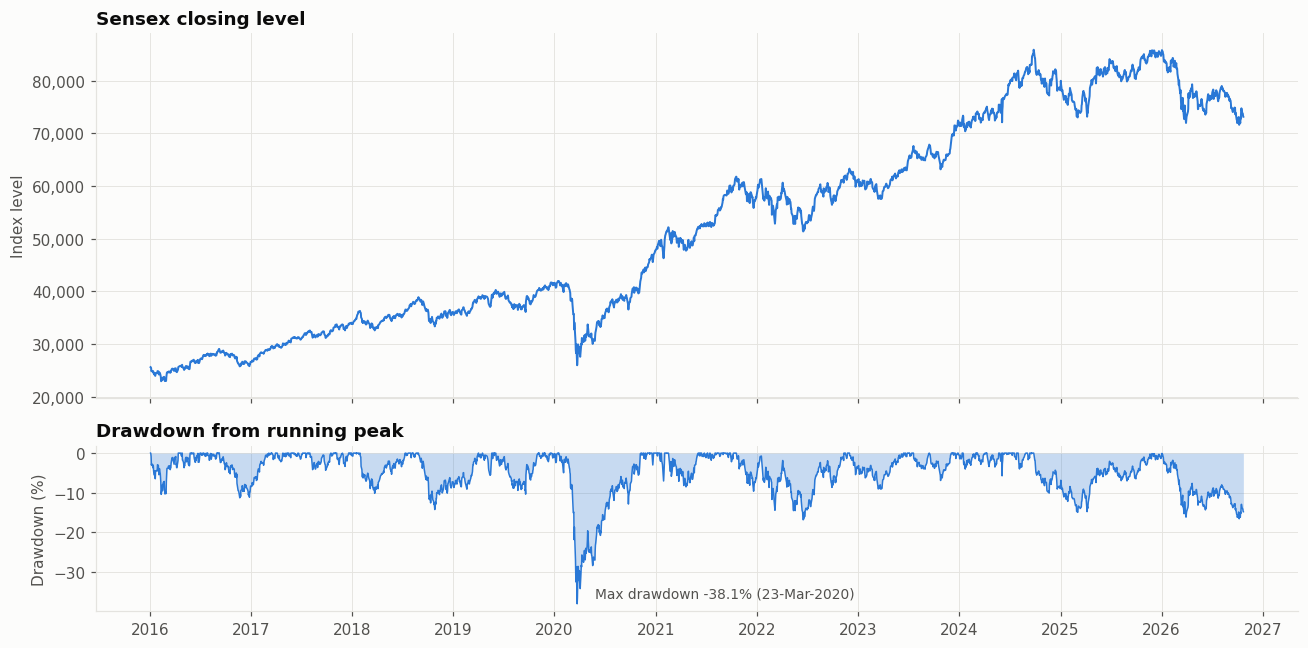

In [11]:
dd = px / px.cummax() - 1
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
ax1.plot(px.index, px, color=PALETTE[0], lw=1.3)
ax1.set_title('Sensex closing level'); ax1.set_ylabel('Index level'); ax1.yaxis.set_major_formatter(thousands)
ax2.fill_between(dd.index, 100 * dd, 0, color=PALETTE[0], alpha=0.25, lw=0)
ax2.plot(dd.index, 100 * dd, color=PALETTE[0], lw=1)
trough = dd.idxmin()
ax2.annotate(f'Max drawdown {dd.min():.1%} ({trough:%d-%b-%Y})', xy=(trough, 100 * dd.min()), xytext=(12, 4),
             textcoords='offset points', fontsize=9, color=INK2)
ax2.set_title('Drawdown from running peak'); ax2.set_ylabel('Drawdown (%)')
ax2.xaxis.set_major_locator(mdates.YearLocator()); ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout(); save(fig, '01_price_drawdown'); plt.show()

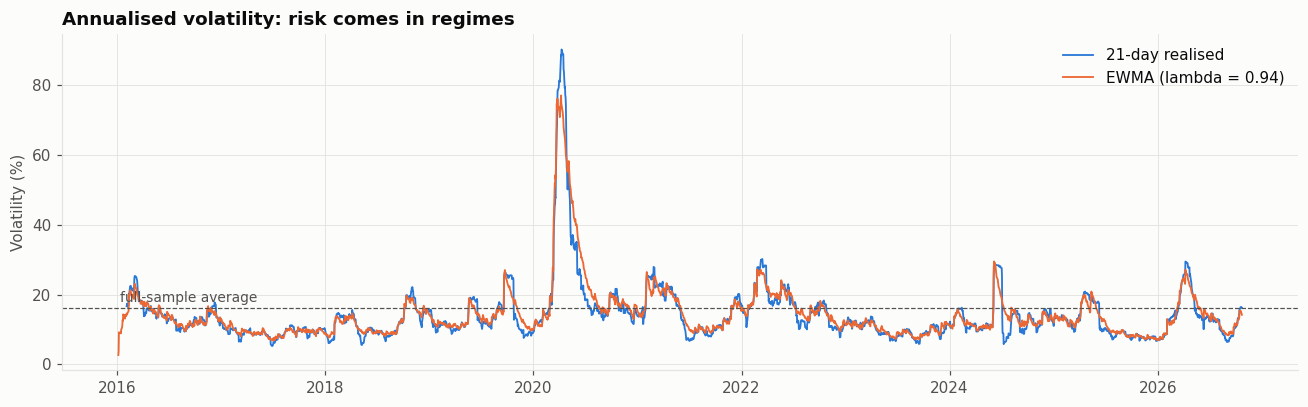

In [12]:
roll_vol = ret.rolling(21).std() * np.sqrt(252) * 100
ewma_var = ret.pow(2).ewm(alpha=1 - LAM, adjust=False).mean()          # includes day t -> forecast for t+1
ewma_vol = np.sqrt(ewma_var * 252) * 100
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(roll_vol.index, roll_vol, color=PALETTE[0], lw=1.2, label='21-day realised')
ax.plot(ewma_vol.index, ewma_vol, color=PALETTE[1], lw=1.2, label=f'EWMA (lambda = {LAM})')
ax.axhline(100 * ret.std() * np.sqrt(252), color=INK2, lw=0.8, ls='--')
ax.text(ret.index[5], 100 * ret.std() * np.sqrt(252) + 1.5, 'full-sample average', color=INK2, fontsize=9)
ax.set_title('Annualised volatility: risk comes in regimes'); ax.set_ylabel('Volatility (%)'); ax.legend(loc='upper right')
fig.tight_layout(); save(fig, '02_volatility_regimes'); plt.show()

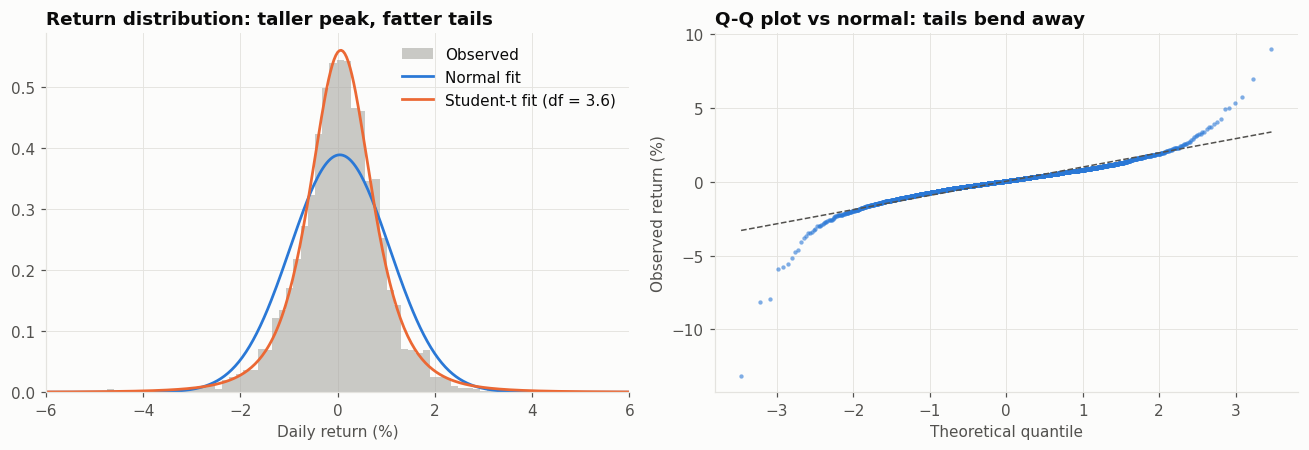

In [13]:
t_params = stats.t.fit(ret)
grid = np.linspace(ret.min(), ret.max(), 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.hist(100 * ret, bins=150, density=True, color=NEUTRAL, alpha=0.6, label='Observed')
ax1.plot(100 * grid, stats.norm.pdf(grid, ret.mean(), ret.std()) / 100, color=PALETTE[0], lw=1.8, label='Normal fit')
ax1.plot(100 * grid, stats.t.pdf(grid, *t_params) / 100, color=PALETTE[1], lw=1.8, label=f'Student-t fit (df = {t_params[0]:.1f})')
ax1.set_xlim(-6, 6); ax1.set_title('Return distribution: taller peak, fatter tails'); ax1.set_xlabel('Daily return (%)'); ax1.legend()
(osm, osr), (slope, intercept, _) = stats.probplot(ret, dist='norm')
ax2.scatter(osm, 100 * osr, s=8, color=PALETTE[0], alpha=0.6, lw=0)
ax2.plot(osm, 100 * (slope * osm + intercept), color=INK2, lw=1, ls='--')
ax2.set_title('Q-Q plot vs normal: tails bend away'); ax2.set_xlabel('Theoretical quantile'); ax2.set_ylabel('Observed return (%)')
fig.tight_layout(); save(fig, '03_distribution_qq'); plt.show()

## 5 · Anomaly detection: from a fixed threshold to a triaged exceptions register
The original flagged days with |return| > 5%. A fixed threshold ignores the **volatility regime**: a −3% day in a calm market is far more unusual than a −5% day in March 2020. Three independent methods are combined:

| Method | Logic | Strength |
|---|---|---|
| Fixed threshold | \|return\| > 5% (original rule) | Simple, explainable |
| Volatility-adjusted | \|return / EWMA σ forecast\| > 4, using only information available the day before (no look-ahead) | Adapts to regime |
| Isolation Forest | Unsupervised ML on return, opening gap, intraday range and z-score | Catches unusual *combinations* |

Days flagged by two or more methods get **High** triage priority, which is how a continuous-monitoring tool focuses an auditor's time.

In [14]:
ewma_sd_fcst = np.sqrt(ret.pow(2).ewm(alpha=1 - LAM, adjust=False).mean().shift(1))   # info up to t-1 only
feat = pd.DataFrame({
    'prev_close': px.shift(1), 'close': px, 'ret': px.pct_change(),
    'gap': clean['Open'] / px.shift(1) - 1,
    'range': (clean['High'] - clean['Low']) / px.shift(1),
}).loc[ret.index]
feat['z_vol_adj'] = feat['ret'] / ewma_sd_fcst
feat = feat.iloc[20:].dropna()        # EWMA warm-up

feat['flag_fixed_5pct'] = feat['ret'].abs() > 0.05
feat['flag_vol_adjusted'] = feat['z_vol_adj'].abs() > 4
X = feat[['ret', 'gap', 'range', 'z_vol_adj']]
X = (X - X.mean()) / X.std()
iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=CFG['seed']).fit(X)
feat['flag_isolation_forest'] = iso.predict(X) == -1
FLAGS = ['flag_fixed_5pct', 'flag_vol_adjusted', 'flag_isolation_forest']
feat['n_methods'] = feat[FLAGS].sum(axis=1)

EVENTS = {   # analyst annotations: corroborate against a news source before citing in a report
    '2019-09-20': 'Corporate tax cut announced', '2020-03-12': 'COVID-19 declared a pandemic',
    '2020-03-23': 'COVID-19 crash, lockdowns', '2020-04-07': 'COVID-19 relief rally',
    '2020-05-04': 'Lockdown extension sell-off', '2021-02-01': 'Union Budget rally',
    '2022-02-24': 'Russia invades Ukraine', '2024-06-03': 'Election exit-poll rally',
    '2024-06-04': 'Election results sell-off',
}
register = feat[feat['n_methods'] > 0].copy()
register['priority'] = np.where(register['n_methods'] >= 2, 'High', 'Medium')
register['context'] = pd.Series(register.index.strftime('%Y-%m-%d'), index=register.index).map(EVENTS).fillna('')
register = register.reindex(register['ret'].abs().sort_values(ascending=False).index).sort_values('n_methods', ascending=False, kind='stable')

overlap = (feat.loc[feat['n_methods'] > 0, FLAGS]
           .apply(lambda r: ' + '.join(c.replace('flag_', '') for c in FLAGS if r[c]), axis=1).value_counts())
print(f"Flagged days: {len(register)}  |  High priority (2+ methods): {(register['priority'] == 'High').sum()}")
display(overlap.rename('days').to_frame())

view = register.head(15)[['prev_close', 'close', 'ret', 'z_vol_adj', 'n_methods', 'priority', 'context']].copy()
view['ret'] = (100 * view['ret']).round(2)
view.rename(columns={'ret': 'return_%', 'z_vol_adj': 'z_score'})

Flagged days: 29  |  High priority (2+ methods): 15


,days
isolation_forest,12
fixed_5pct + isolation_forest,7
fixed_5pct + vol_adjusted + isolation_forest,5
vol_adjusted + isolation_forest,3
vol_adjusted,2


,prev_close,close,return_%,z_score,n_methods,priority,context
Date,,,,,,,
2020-03-12,"35,697.40","32,778.14",-8.18,-4.83,3,High,COVID-19 declared a pandemic
2024-06-04,"76,468.78","72,079.05",-5.74,-5.45,3,High,Election results sell-off
2019-09-20,"36,093.47","38,014.62",5.32,5.53,3,High,Corporate tax cut announced
2020-03-09,"37,576.62","35,634.95",-5.17,-4.16,3,High,
2021-02-01,"46,285.77","48,600.61",5.00,4.69,3,High,Union Budget rally
2020-03-23,"29,915.96","25,981.24",-13.15,-3.72,2,High,"COVID-19 crash, lockdowns"
2020-04-07,"27,590.95","30,067.21",8.97,2.01,2,High,COVID-19 relief rally
2020-03-16,"34,103.48","31,390.07",-7.96,-2.95,2,High,
2020-03-25,"26,674.03","28,535.78",6.98,1.51,2,High,


Volatility-adjusted rule catches 5 days the fixed 5% rule misses, for example:
   03-Jun-2024: return +3.39% but z = +5.1 (a calm market made it unusual)
   20-May-2019: return +3.75% but z = +4.8 (a calm market made it unusual)
   03-Feb-2026: return +2.54% but z = +4.6 (a calm market made it unusual)
   02-Feb-2018: return -2.34% but z = -4.3 (a calm market made it unusual)

It also drops 7 "5% days" that were ordinary for their high-volatility regime (mostly March-April 2020).


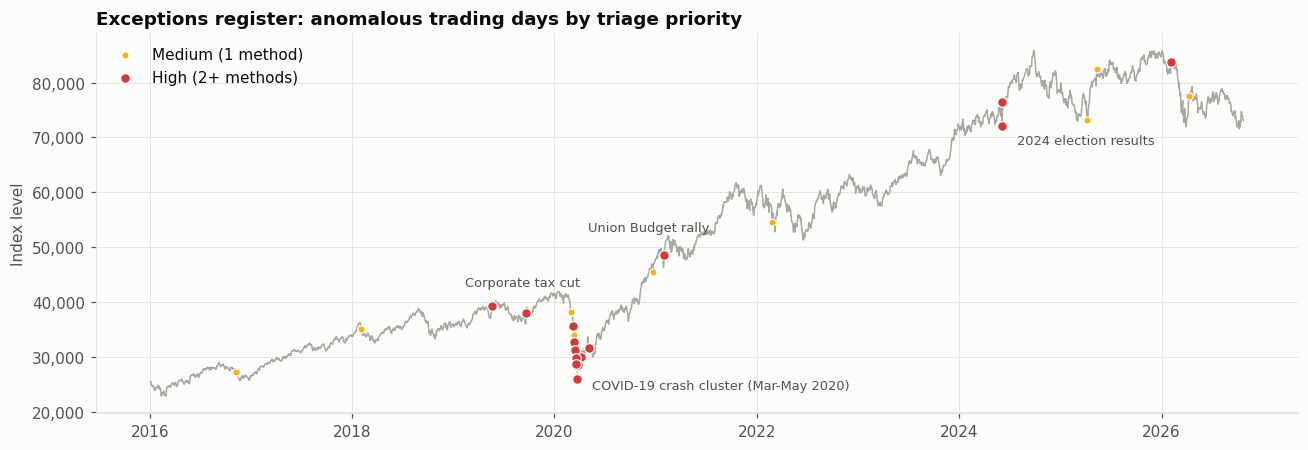

In [15]:
vol_only = feat[feat['flag_vol_adjusted'] & ~feat['flag_fixed_5pct']]
fixed_only = feat[feat['flag_fixed_5pct'] & ~feat['flag_vol_adjusted']]
print(f'Volatility-adjusted rule catches {len(vol_only)} days the fixed 5% rule misses, for example:')
for d, r in vol_only.reindex(vol_only['z_vol_adj'].abs().sort_values(ascending=False).index).head(4).iterrows():
    print(f"   {d:%d-%b-%Y}: return {r['ret']:+.2%} but z = {r['z_vol_adj']:+.1f} (a calm market made it unusual)")
print(f'\nIt also drops {len(fixed_only)} "5% days" that were ordinary for their high-volatility regime (mostly March-April 2020).')

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(px.index, px, color=NEUTRAL, lw=1)
med, high = register[register['priority'] == 'Medium'], register[register['priority'] == 'High']
ax.scatter(med.index, med['close'], s=22, color=STATUS['warning'], edgecolor=SURFACE, lw=0.8, zorder=3, label='Medium (1 method)')
ax.scatter(high.index, high['close'], s=40, color=STATUS['critical'], edgecolor=SURFACE, lw=0.8, zorder=4, label='High (2+ methods)')
LABELS = {'2019-09-20': ('Corporate tax cut', (-40, 18)), '2020-03-23': ('COVID-19 crash cluster (Mar-May 2020)', (10, -6)),
          '2021-02-01': ('Union Budget rally', (-50, 16)), '2024-06-04': ('2024 election results', (10, -12))}
for d, (label, offset) in LABELS.items():
    if pd.Timestamp(d) in register.index:
        ax.annotate(label, xy=(pd.Timestamp(d), register.loc[d, 'close']), xytext=offset, textcoords='offset points', fontsize=8.5, color=INK2)
ax.set_title('Exceptions register: anomalous trading days by triage priority'); ax.set_ylabel('Index level')
ax.yaxis.set_major_formatter(thousands); ax.legend(loc='upper left')
fig.tight_layout(); save(fig, '04_anomalies'); plt.show()

## 6 · Monte Carlo simulation (vectorised, three return models)
The original used a nested Python loop, zero drift and normal shocks, and built the DataFrame one column at a time (hence the fragmentation warnings). Here 10,000 one-year paths per model are generated in a single NumPy operation, and three return models are compared:
* **GBM**: normal log-returns (the textbook model).
* **Student-t**: fitted fat-tailed shocks.
* **Bootstrap**: resampled historical returns, so no distribution is assumed.

A **convergence test** then shows how precise the estimate is for a given number of paths. This is the judgement step: how many paths are enough?

In [16]:
S0, T, N = px.iloc[-1], CFG['sim_days'], CFG['n_sims']
mu_d, sd_d = logret.mean(), logret.std()
t_nu, t_loc, t_scale = stats.t.fit(logret)
sim_rng = np.random.default_rng(CFG['seed'])
log_shocks = {
    'GBM (normal)': sim_rng.normal(mu_d, sd_d, size=(T, N)),
    'Student-t': stats.t.rvs(t_nu, loc=t_loc, scale=t_scale, size=(T, N), random_state=sim_rng),
    'Bootstrap (historical)': sim_rng.choice(logret.values, size=(T, N), replace=True),
}
paths = {k: S0 * np.exp(np.cumsum(v, axis=0)) for k, v in log_shocks.items()}

rows = []
for k, p in paths.items():
    term = p[-1] / S0 - 1
    q = np.quantile(term, 0.01)
    rows.append({'model': k, 'median level in 1y': np.median(p[-1]),
                 '5th pct level': np.percentile(p[-1], 5), '95th pct level': np.percentile(p[-1], 95),
                 'P(loss after 1y) %': 100 * (term < 0).mean(),
                 '1y 99% VaR (INR)': -q * POS, '1y 99% ES (INR)': -term[term <= q].mean() * POS})
mc_summary = pd.DataFrame(rows).set_index('model')
print(f'Start level {S0:,.2f} | {N:,} paths x {T} days per model | position INR {POS:,.0f}')
lo_m, hi_m = mc_summary['1y 99% VaR (INR)'].idxmin(), mc_summary['1y 99% VaR (INR)'].idxmax()
print(f"Model risk: 1y 99% VaR ranges from INR {mc_summary.loc[lo_m, '1y 99% VaR (INR)']:,.0f} ({lo_m}) to "
      f"INR {mc_summary.loc[hi_m, '1y 99% VaR (INR)']:,.0f} ({hi_m}) on the same data.")
if lo_m == 'Student-t':
    print(f'  The Student-t is symmetric: it captures fat tails but not the negative skew ({stats.skew(logret):.2f}), '
          'so its centre sits too high and it is the most optimistic. Model choice is itself a risk to disclose.')
mc_summary

Start level 73,123.83 | 10,000 paths x 252 days per model | position INR 10,000,000
Model risk: 1y 99% VaR ranges from INR 1,939,942 (Student-t) to INR 2,525,942 (Bootstrap (historical)) on the same data.
  The Student-t is symmetric: it captures fat tails but not the negative skew (-1.28), so its centre sits too high and it is the most optimistic. Model choice is itself a risk to disclose.


,median level in 1y,5th pct level,95th pct level,P(loss after 1y) %,1y 99% VaR (INR),1y 99% ES (INR)
model,,,,,,
GBM (normal),"80,815.99","61,595.83","105,901.72",26.71,"2,474,601.67","2,794,698.64"
Student-t,"86,008.71","66,037.54","111,680.81",15.34,"1,939,942.15","2,327,468.15"
Bootstrap (historical),"80,745.61","61,396.15","105,491.61",27.15,"2,525,942.17","2,975,268.73"


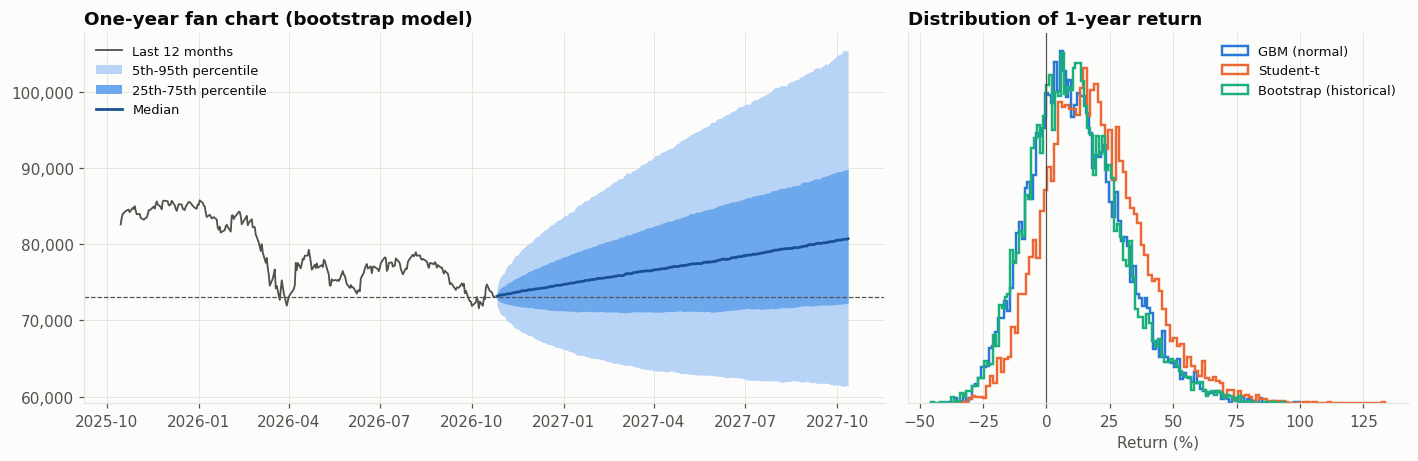

In [17]:
p = paths['Bootstrap (historical)']
future = pd.bdate_range(px.index[-1] + pd.Timedelta(days=1), periods=T)
b05, b25, b50, b75, b95 = np.percentile(p, [5, 25, 50, 75, 95], axis=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1.6, 1]})
ax1.plot(px.index[-252:], px.iloc[-252:], color=INK2, lw=1.2, label='Last 12 months')
ax1.fill_between(future, b05, b95, color='#b7d3f6', lw=0, label='5th-95th percentile')
ax1.fill_between(future, b25, b75, color='#6da7ec', lw=0, label='25th-75th percentile')
ax1.plot(future, b50, color='#184f95', lw=1.8, label='Median')
ax1.axhline(S0, color=INK2, lw=0.8, ls='--')
ax1.set_title('One-year fan chart (bootstrap model)'); ax1.yaxis.set_major_formatter(thousands); ax1.legend(loc='upper left', fontsize=8.5)
for k, color in zip(paths, PALETTE):
    ax2.hist(100 * (paths[k][-1] / S0 - 1), bins=120, histtype='step', lw=1.6, color=color, density=True, label=k)
ax2.axvline(0, color=INK2, lw=0.8)
ax2.set_title('Distribution of 1-year return'); ax2.set_xlabel('Return (%)'); ax2.set_yticks([]); ax2.legend(fontsize=8.5)
fig.tight_layout(); save(fig, '05_monte_carlo'); plt.show()

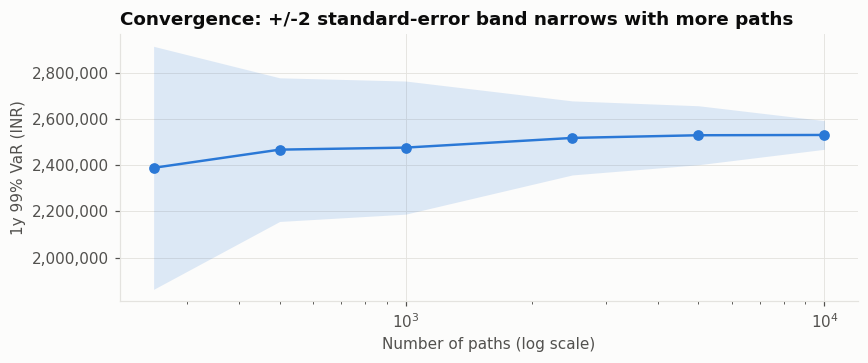

,paths,mean 1y 99% VaR (INR),std error (INR),relative error %
0,250,"2,388,349.89","262,809.25",11.00
1,500,"2,467,044.51","155,342.54",6.30
2,1000,"2,475,882.69","143,936.49",5.81
3,2500,"2,517,733.12","80,067.67",3.18
4,5000,"2,529,298.52","63,794.31",2.52
5,10000,"2,530,546.33","31,000.20",1.23


In [18]:
conv_rng = np.random.default_rng(CFG['seed'] + 1)
lr = logret.values
conv = []
for n in [250, 500, 1_000, 2_500, 5_000, 10_000]:
    est = [-np.quantile(np.expm1(conv_rng.choice(lr, size=(T, n)).sum(axis=0)), 0.01) * POS for _ in range(30)]
    conv.append({'paths': n, 'mean 1y 99% VaR (INR)': np.mean(est), 'std error (INR)': np.std(est),
                 'relative error %': 100 * np.std(est) / np.mean(est)})
conv = pd.DataFrame(conv)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(conv['paths'], conv['mean 1y 99% VaR (INR)'], marker='o', color=PALETTE[0])
ax.fill_between(conv['paths'], conv['mean 1y 99% VaR (INR)'] - 2 * conv['std error (INR)'],
                conv['mean 1y 99% VaR (INR)'] + 2 * conv['std error (INR)'], color=PALETTE[0], alpha=0.15, lw=0)
ax.set_xscale('log'); ax.yaxis.set_major_formatter(thousands)
ax.set_title('Convergence: +/-2 standard-error band narrows with more paths'); ax.set_xlabel('Number of paths (log scale)'); ax.set_ylabel('1y 99% VaR (INR)')
fig.tight_layout(); save(fig, '06_mc_convergence'); plt.show()
conv

## 7 · Value-at-Risk & Expected Shortfall: six methods side by side
**VaR** answers "what loss will not be exceeded with X% confidence?". **Expected Shortfall (ES)** answers "if it *is* exceeded, how bad is the average loss?". Regulators moved from VaR to ES (FRTB) because VaR says nothing about the tail beyond it.

| Method | Idea |
|---|---|
| Parametric normal | μ − zσ (the original approach, now with 99% and ES) |
| Historical simulation | Empirical quantile of actual returns, no distribution assumed |
| Cornish-Fisher | Normal quantile adjusted for skew and kurtosis |
| Student-t | Quantile of a fitted fat-tailed distribution |
| EWMA (RiskMetrics) | Normal, using *current* volatility (λ = 0.94) |
| Filtered historical | Historical shapes rescaled to current EWMA volatility |

The 10-day figures use √10 scaling, which is a stated assumption (independent returns, no portfolio changes during the horizon).

In [19]:
def var_es_table(r, position, conf_levels, horizon, lam, seed):
    mu, sd, s, k = r.mean(), r.std(), stats.skew(r), stats.kurtosis(r)
    ewma_series = np.sqrt(r.pow(2).ewm(alpha=1 - lam, adjust=False).mean())
    ewma_now = ewma_series.iloc[-1]
    std_resid = (r / ewma_series.shift(1)).dropna()
    nu, loc, scale = stats.t.fit(r)
    t_draws = stats.t.rvs(nu, loc=loc, scale=scale, size=500_000, random_state=np.random.default_rng(seed))
    rows = []
    for c in conf_levels:
        a = 1 - c
        z = stats.norm.ppf(a)
        zcf = z + (z**2 - 1) * s / 6 + (z**3 - 3*z) * k / 24 - (2*z**3 - 5*z) * s**2 / 36
        q_hist, q_t, q_res = np.quantile(r, a), np.quantile(t_draws, a), np.quantile(std_resid, a)
        methods = {
            'Parametric normal': (-(mu + z * sd), -(mu - sd * stats.norm.pdf(z) / a)),
            'Historical simulation': (-q_hist, -r[r <= q_hist].mean()),
            'Cornish-Fisher': (-(mu + zcf * sd), np.nan),
            'Student-t': (-q_t, -t_draws[t_draws <= q_t].mean()),
            'EWMA (current vol)': (-z * ewma_now, ewma_now * stats.norm.pdf(z) / a),
            'Filtered historical': (-q_res * ewma_now, -std_resid[std_resid <= q_res].mean() * ewma_now),
        }
        for m, (v, e) in methods.items():
            rows.append({'method': m, 'confidence': f'{c:.0%}', '1d VaR %': 100 * v, '1d ES %': 100 * e,
                         '1d VaR (INR)': v * position, '1d ES (INR)': e * position,
                         f'{horizon}d VaR (INR)': v * position * np.sqrt(horizon),
                         f'{horizon}d ES (INR)': e * position * np.sqrt(horizon)})
    return pd.DataFrame(rows)

var_table = var_es_table(ret, POS, CFG['conf_levels'], CFG['horizon_days'], LAM, CFG['seed'])
print(f'Position: INR {POS:,.0f} long Sensex | sample {ret.index.min():%b-%Y} to {ret.index.max():%b-%Y}')
cf99, hs99 = (var_table.query("confidence == '99%'").set_index('method').loc[m, '1d VaR %'] for m in ['Cornish-Fisher', 'Historical simulation'])
if cf99 > 1.5 * hs99:
    print(f'Judgement call: Cornish-Fisher 99% VaR ({cf99:.2f}%) is {cf99 / hs99:.1f}x the historical figure. With excess kurtosis of '
          f'{stats.kurtosis(ret):.1f} the expansion is outside its valid range, so it is reported for transparency but excluded from the chart and from model selection.')
var_table

Position: INR 10,000,000 long Sensex | sample Jan-2016 to Oct-2026
Judgement call: Cornish-Fisher 99% VaR (7.23%) is 2.8x the historical figure. With excess kurtosis of 18.9 the expansion is outside its valid range, so it is reported for transparency but excluded from the chart and from model selection.


,method,confidence,1d VaR %,1d ES %,1d VaR (INR),1d ES (INR),10d VaR (INR),10d ES (INR)
0,Parametric normal,95%,1.64,2.07,"164,022.60","206,826.86","518,685.02","654,043.97"
1,Historical simulation,95%,1.44,2.34,"143,948.89","234,147.89","455,206.37","740,440.64"
2,Cornish-Fisher,95%,1.51,NaN,"150,955.88",NaN,"477,364.39",NaN
3,Student-t,95%,1.40,2.19,"139,670.79","219,338.41","441,677.83","693,608.95"
4,EWMA (current vol),95%,1.47,1.84,"147,017.42","184,365.77","464,909.89","583,015.76"
5,Filtered historical,95%,1.55,2.16,"154,536.94","216,390.41","488,688.72","684,286.55"
6,Parametric normal,99%,2.34,2.69,"233,832.86","268,545.32","739,444.42","849,214.87"
7,Historical simulation,99%,2.62,4.36,"261,562.48","435,756.30","827,133.19","1,377,982.42"
8,Cornish-Fisher,99%,7.23,NaN,"722,503.70",NaN,"2,284,757.31",NaN
9,Student-t,99%,2.58,3.75,"258,298.19","374,923.09","816,810.60","1,185,610.92"


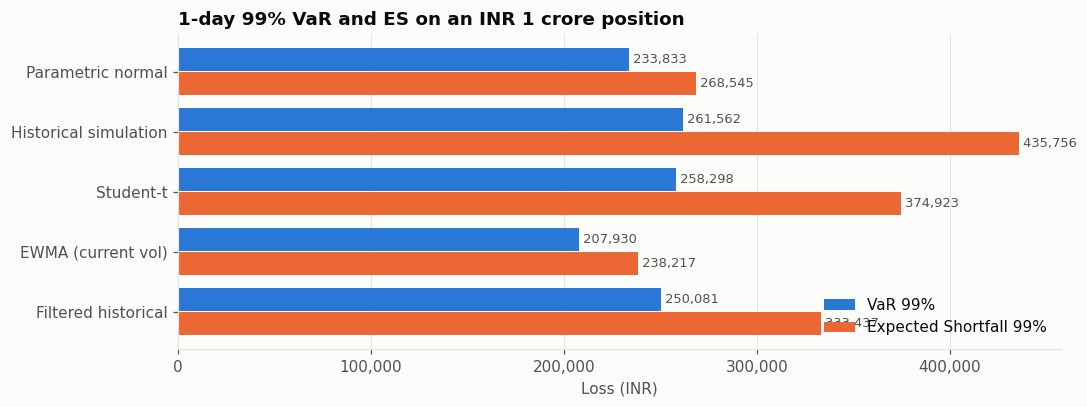

In [20]:
v99 = var_table[var_table['confidence'] == '99%'].set_index('method')
v99_plot = v99.drop(index='Cornish-Fisher')
y = np.arange(len(v99_plot))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(y - 0.2, v99_plot['1d VaR (INR)'], height=0.38, color=PALETTE[0], label='VaR 99%')
ax.barh(y + 0.2, v99_plot['1d ES (INR)'], height=0.38, color=PALETTE[1], label='Expected Shortfall 99%')
for i, (v, e) in enumerate(zip(v99_plot['1d VaR (INR)'], v99_plot['1d ES (INR)'])):
    ax.text(v, i - 0.2, f' {v:,.0f}', va='center', fontsize=8.5, color=INK2)
    ax.text(e, i + 0.2, f' {e:,.0f}', va='center', fontsize=8.5, color=INK2)
ax.set_yticks(y, v99_plot.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(thousands)
ax.set_title(f'1-day 99% VaR and ES on an INR {POS/1e7:.0f} crore position'); ax.set_xlabel('Loss (INR)')
ax.legend(loc='lower right'); ax.grid(axis='y', visible=False)
fig.tight_layout(); save(fig, '07_var_es_methods'); plt.show()

## 8 · Stress testing
VaR describes *normal* bad days. Stress tests ask what happens beyond them. Four lenses are used:
1. **Volatility regimes**, with corrected √252 scaling (fixes finding F-01).
2. **Historical replay**: the worst actual 1/5/20/60-day windows and the largest drawdown.
3. **Hypothetical shocks**: instantaneous index falls.
4. **Reverse stress test**: how big a move would use up a capital buffer, and how often has that happened?

In [21]:
peak_vol, peak_date = roll_vol.max() / 100, roll_vol.idxmax()
ewma_now_ann = np.sqrt(ewma_var.iloc[-1] * 252)
regimes = [('Full-sample realised', ret.std() * np.sqrt(252)), ('Current EWMA', ewma_now_ann),
           ('Elevated (20%)', 0.20), ('High (25%)', 0.25), ('Severe (40%)', 0.40),
           (f'Historical 21d peak ({peak_date:%b-%Y})', peak_vol)]
vol_stress = pd.DataFrame([{'scenario': n, 'annual vol %': 100 * v, 'daily vol %': 100 * v / np.sqrt(252),
                            '1d VaR 99% (INR)': POS * z99 * v / np.sqrt(252),
                            '10d VaR 99% (INR)': POS * z99 * v / np.sqrt(252) * np.sqrt(10),
                            '1d ES 99% (INR)': POS * v / np.sqrt(252) * stats.norm.pdf(z99) / 0.01} for n, v in regimes])
vol_stress

,scenario,annual vol %,daily vol %,1d VaR 99% (INR),10d VaR 99% (INR),1d ES 99% (INR)
0,Full-sample realised,16.26,1.02,"238,304.19","753,584.01","273,016.65"
1,Current EWMA,14.19,0.89,"207,929.54","657,530.93","238,217.50"
2,Elevated (20%),20.00,1.26,"293,092.28","926,839.18","335,785.43"
3,High (25%),25.00,1.57,"366,365.35","1,158,548.97","419,731.79"
4,Severe (40%),40.00,2.52,"586,184.57","1,853,678.36","671,570.86"
5,Historical 21d peak (Apr-2020),90.23,5.68,"1,322,243.78","4,181,301.96","1,514,847.78"


In [22]:
hist_rows = []
for h in [1, 5, 20, 60]:
    r_h = px.pct_change(h)
    end = r_h.idxmin()
    start = px.index[px.index.get_loc(end) - h]
    hist_rows.append({'scenario': f'Worst {h}-day window', 'from': start.date(), 'to': end.date(), 'index move %': 100 * r_h.min()})
trough = dd.idxmin(); peak = px.loc[:trough].idxmax()
after = px.loc[trough:]; recovered = after[after >= px.loc[peak]].index.min()
hist_rows.append({'scenario': 'Largest peak-to-trough drawdown', 'from': peak.date(), 'to': trough.date(), 'index move %': 100 * dd.min()})
for d in ['2024-06-04', '2022-02-24']:
    if pd.Timestamp(d) in ret.index:
        hist_rows.append({'scenario': EVENTS[d], 'from': pd.Timestamp(d).date(), 'to': pd.Timestamp(d).date(), 'index move %': 100 * ret.loc[d]})
for s in [-0.05, -0.10, -0.15, -0.20, -0.30]:
    hist_rows.append({'scenario': f'Hypothetical {s:.0%} gap down', 'from': '', 'to': '', 'index move %': 100 * s})
stress = pd.DataFrame(hist_rows)
stress['P&L (INR)'] = POS * stress['index move %'] / 100
hist_var99 = v99.loc['Historical simulation', '1d VaR (INR)']
stress['x 1d hist VaR99'] = -stress['P&L (INR)'] / hist_var99
print(f"Drawdown: peak {peak:%d-%b-%Y} -> trough {trough:%d-%b-%Y} -> "
      f"{'recovered ' + format(recovered, '%d-%b-%Y') + f' ({(recovered - trough).days} days)' if pd.notna(recovered) else 'not yet recovered'}")
stress

Drawdown: peak 14-Jan-2020 -> trough 23-Mar-2020 -> recovered 09-Nov-2020 (231 days)


,scenario,from,to,index move %,P&L (INR),x 1d hist VaR99
0,Worst 1-day window,2020-03-20,2020-03-23,-13.15,"-1,315,258.00",5.03
1,Worst 5-day window,2020-03-11,2020-03-18,-19.13,"-1,912,713.24",7.31
2,Worst 20-day window,2020-02-20,2020-03-23,-36.89,"-3,689,297.11",14.10
3,Worst 60-day window,2019-12-24,2020-03-23,-37.34,"-3,733,610.81",14.27
4,Largest peak-to-trough drawdown,2020-01-14,2020-03-23,-38.07,"-3,807,005.45",14.55
5,Election results sell-off,2024-06-04,2024-06-04,-5.74,"-574,055.75",2.19
6,Russia invades Ukraine,2022-02-24,2022-02-24,-4.72,"-472,138.96",1.81
7,Hypothetical -5% gap down,,,-5.00,"-500,000.00",1.91
8,Hypothetical -10% gap down,,,-10.00,"-1,000,000.00",3.82
9,Hypothetical -15% gap down,,,-15.00,"-1,500,000.00",5.73


Capital buffer (3 x 10d hist VaR99): INR 2,481,400  = 24.8% of the position
A 10-day fall of -24.8% or worse would exhaust it.
Overlapping 10-day windows that breached it: 4 of 2,651 (0.15%), all between 18-Mar-2020 and 24-Mar-2020


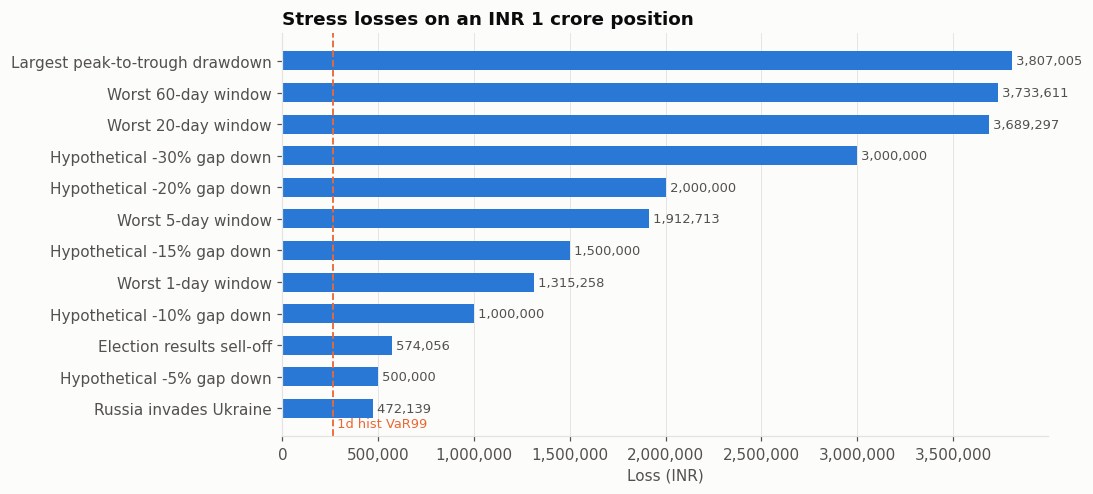

In [23]:
# Reverse stress test: what 10-day fall exhausts a Basel-style capital buffer of 3 x 10-day historical VaR99?
buffer = 3 * v99.loc['Historical simulation', '10d VaR (INR)']
breaking_move = -buffer / POS
r10 = px.pct_change(10).dropna()
n_breach = int((r10 <= breaking_move).sum())
print(f'Capital buffer (3 x 10d hist VaR99): INR {buffer:,.0f}  = {buffer/POS:.1%} of the position')
print(f'A 10-day fall of {breaking_move:.1%} or worse would exhaust it.')
print(f'Overlapping 10-day windows that breached it: {n_breach} of {len(r10):,} ({n_breach/len(r10):.2%})'
      + (f', all between {r10[r10 <= breaking_move].index.min():%d-%b-%Y} and {r10[r10 <= breaking_move].index.max():%d-%b-%Y}' if n_breach else ''))

plot_df = stress.sort_values('P&L (INR)')
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(plot_df['scenario'], -plot_df['P&L (INR)'], color=PALETTE[0], height=0.6)
for i, v in enumerate(-plot_df['P&L (INR)']):
    ax.text(v, i, f' {v:,.0f}', va='center', fontsize=8.5, color=INK2)
ax.axvline(hist_var99, color=PALETTE[1], lw=1.2, ls='--')
ax.text(hist_var99, len(plot_df) - 0.4, ' 1d hist VaR99', color=PALETTE[1], fontsize=8.5)
ax.invert_yaxis(); ax.xaxis.set_major_formatter(thousands); ax.grid(axis='y', visible=False)
ax.set_title(f'Stress losses on an INR {POS/1e7:.0f} crore position'); ax.set_xlabel('Loss (INR)')
fig.tight_layout(); save(fig, '08_stress_losses'); plt.show()

## 9 · VaR backtesting: does the model actually work?
This addresses the most serious gap in the original (finding F-02). Each day, every model produces a 99% VaR forecast using **only the previous 250 days**. That forecast is compared with the next day's actual return. A loss bigger than the VaR is an **exception**. At 99% confidence about 1 exception per 100 days is expected.

| Test | Question | Reject if p < 0.05 |
|---|---|---|
| **Kupiec POF** | Is the *number* of exceptions consistent with 1%? | Too many (under-reserving) or too few (over-reserving) |
| **Christoffersen independence** | Do exceptions *cluster*? | The model is slow to react to new volatility |
| **Conditional coverage** | Both together (χ² with 2 df) | Combined failure |
| **Basel traffic light** | Exceptions in the latest 250 days | Green ≤ 4 · Yellow 5–9 · Red ≥ 10 |

The average VaR level is also shown. A model that passes only because it always holds too much capital is not "good". It is expensive.

In [24]:
W, A = CFG['backtest_window'], 0.01
z01 = stats.norm.ppf(A)
ewma_fcst = np.sqrt(ret.pow(2).ewm(alpha=1 - LAM, adjust=False).mean().shift(1))
std_resid = ret / ewma_fcst
forecasts = pd.DataFrame({
    'Normal':      -(ret.rolling(W).mean().shift(1) + z01 * ret.rolling(W).std().shift(1)),
    'Historical':  -ret.rolling(W).quantile(A).shift(1),
    'EWMA':        -(z01 * ewma_fcst),
    'Filtered HS': -(std_resid.rolling(W).quantile(A).shift(1) * ewma_fcst),
}).dropna()
realised = ret.loc[forecasts.index]
hits = forecasts.apply(lambda col: realised < -col)

def kupiec(x, n, p):
    lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - xlogy(n - x, 1 - x / n) - xlogy(x, x / n))
    return lr, stats.chi2.sf(lr, 1)

def christoffersen(h):
    h = h.astype(int).values; a, b = h[:-1], h[1:]
    n00, n01, n10, n11 = ((a == 0) & (b == 0)).sum(), ((a == 0) & (b == 1)).sum(), ((a == 1) & (b == 0)).sum(), ((a == 1) & (b == 1)).sum()
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); p = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll0 = xlogy(n00 + n10, 1 - p) + xlogy(n01 + n11, p)
    ll1 = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11)
    lr = -2 * (ll0 - ll1)
    return lr, stats.chi2.sf(lr, 1)

zone = lambda x: 'Green' if x <= 4 else ('Yellow' if x <= 9 else 'Red')
rolling_ex = hits.rolling(W).sum().dropna()
bt_rows = []
for m in forecasts:
    x, n = int(hits[m].sum()), len(hits)
    lr_pof, p_pof = kupiec(x, n, A)
    lr_ind, p_ind = christoffersen(hits[m])
    p_cc = stats.chi2.sf(lr_pof + lr_ind, 2)
    latest = int(hits[m].iloc[-W:].sum())
    bt_rows.append({'model': m, 'test days': n, 'exceptions': x, 'expected': round(n * A, 1),
                    'exception rate %': 100 * x / n, 'Kupiec p': fmt_p(p_pof), 'Christoffersen p': fmt_p(p_ind),
                    'Cond. coverage p': fmt_p(p_cc), 'latest 250d': f'{latest} ({zone(latest)})',
                    'worst 250d': f'{int(rolling_ex[m].max())} ({zone(rolling_ex[m].max())})',
                    '% of days in Red': 100 * (rolling_ex[m] >= 10).mean(),
                    'avg VaR %': 100 * forecasts[m].mean(),
                    'verdict': 'Accept' if min(p_pof, p_ind) >= 0.05 else 'Reject',
                    '_p_pof': p_pof, '_p_ind': p_ind, '_latest': latest})
backtest = pd.DataFrame(bt_rows).set_index('model')
print(f'Out-of-sample test period: {forecasts.index.min():%d-%b-%Y} to {forecasts.index.max():%d-%b-%Y}')
backtest.drop(columns=[c for c in backtest if c.startswith('_')])

Out-of-sample test period: 11-Jan-2017 to 23-Oct-2026


,test days,exceptions,expected,exception rate %,Kupiec p,Christoffersen p,Cond. coverage p,latest 250d,worst 250d,% of days in Red,avg VaR %,verdict
model,,,,,,,,,,,,
Normal,2409,46,24.10,1.91,<0.001,0.012,<0.001,8 (Yellow),12 (Red),10.05,2.18,Reject
Historical,2409,38,24.10,1.58,0.009,0.023,0.002,6 (Yellow),10 (Red),9.12,2.58,Reject
EWMA,2409,44,24.10,1.83,<0.001,0.201,<0.001,4 (Green),12 (Red),4.91,2.09,Reject
Filtered HS,2409,31,24.10,1.29,0.175,0.369,0.267,4 (Green),8 (Yellow),0.00,2.55,Accept


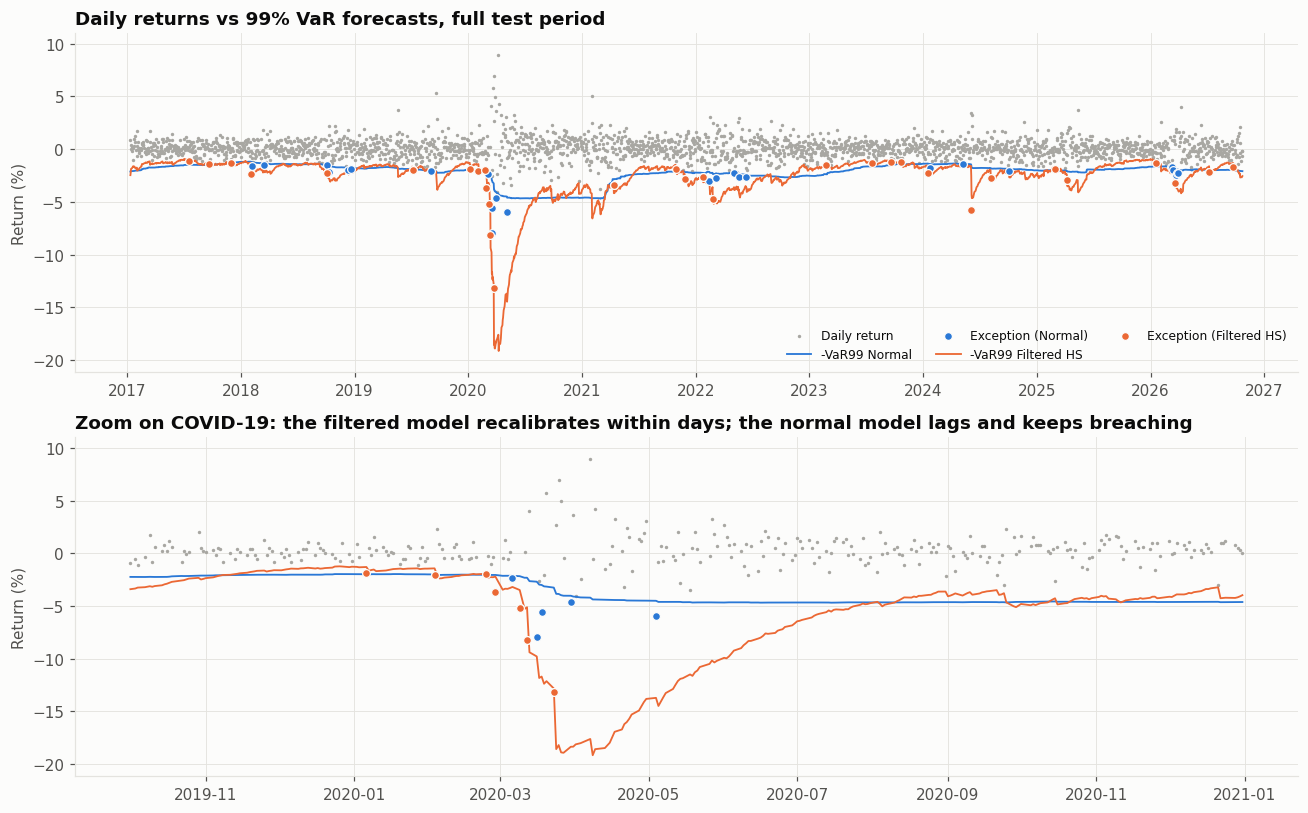

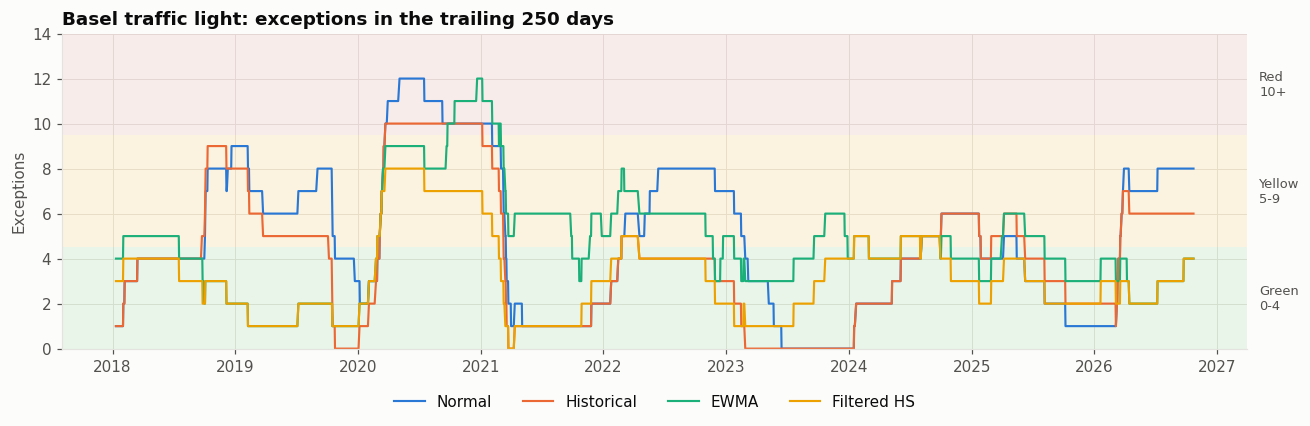

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5))
for ax, (lo, hi), title in [(ax1, (None, None), 'Daily returns vs 99% VaR forecasts, full test period'),
                            (ax2, ('2019-10-01', '2020-12-31'), 'Zoom on COVID-19: the filtered model recalibrates within days; the normal model lags and keeps breaching')]:
    sl = slice(lo, hi)
    floor = min(100 * realised.loc[sl].min(), -100 * forecasts.loc[sl, ['Normal', 'Filtered HS']].max().max())
    ax.set_ylim(floor - 2, 11)
    ax.scatter(realised.loc[sl].index, 100 * realised.loc[sl], s=5, color=NEUTRAL, lw=0, label='Daily return')
    for m, c in [('Normal', PALETTE[0]), ('Filtered HS', PALETTE[1])]:
        ax.plot(forecasts.loc[sl].index, -100 * forecasts.loc[sl, m], color=c, lw=1.2, label=f'-VaR99 {m}')
        ex = hits.loc[sl, m]
        ax.scatter(ex[ex].index, 100 * realised.loc[sl][ex], s=26, color=c, edgecolor=SURFACE, lw=0.8, zorder=4, label=f'Exception ({m})')
    ax.set_title(title); ax.set_ylabel('Return (%)')
ax1.legend(ncol=3, fontsize=8, loc='lower right')
fig.tight_layout(); save(fig, '09_backtest_returns'); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
top = max(12, rolling_ex.max().max() + 2)
ax.axhspan(0, 4.5, color=STATUS['good'], alpha=0.08, lw=0); ax.axhspan(4.5, 9.5, color=STATUS['warning'], alpha=0.12, lw=0)
ax.axhspan(9.5, top, color=STATUS['critical'], alpha=0.08, lw=0)
for yv, lab in [(2.25, 'Green\n0-4'), (7, 'Yellow\n5-9'), ((9.5 + top) / 2, 'Red\n10+')]:
    ax.text(1.01, yv, lab, transform=ax.get_yaxis_transform(), fontsize=8.5, color=INK2, va='center')
for m, c in zip(rolling_ex, PALETTE):
    ax.plot(rolling_ex.index, rolling_ex[m], color=c, lw=1.4, label=m)
ax.set_ylim(0, top); ax.set_title('Basel traffic light: exceptions in the trailing 250 days'); ax.set_ylabel('Exceptions')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4)
fig.tight_layout(); save(fig, '10_traffic_light'); plt.show()

In [26]:
passing = backtest[backtest['verdict'] == 'Accept']
if len(passing):
    best_model = passing['avg VaR %'].idxmin()
    reason = 'passes both the Kupiec and Christoffersen tests and holds the least capital among models that pass'
else:
    best_model = (backtest['exceptions'] - backtest['expected']).abs().idxmin()
    reason = 'no model passes both tests; this one has exception counts closest to expectation'
worst_model = backtest['% of days in Red'].idxmax()
print(f"Recommended model: {best_model}. It {reason}.")
print(f"Weakest model    : {worst_model}. It spent {backtest.loc[worst_model, '% of days in Red']:.1f}% of days in the Red zone "
      f"(Christoffersen p = {backtest.loc[worst_model, 'Christoffersen p']}).")

Recommended model: Filtered HS. It passes both the Kupiec and Christoffersen tests and holds the least capital among models that pass.
Weakest model    : Normal. It spent 10.0% of days in the Red zone (Christoffersen p = 0.012).


## 10 · Multi-asset model portfolio (iShares ETFs)
Wealth platforms such as Aladdin Wealth give advisors **portfolio-level** risk: how risk is spread across holdings and asset classes, how a portfolio would have done in past crises, and when it has drifted from its model. This section builds an illustrative "Moderate" model: **55% equity, 35% fixed income, 10% gold**.

Things to look for:
* **Weight ≠ risk.** Equities dominate risk even though they are only about half the weight.
* **Diversification depends on the regime.** In 2022 stocks and bonds fell *together*, which was the failure case for 60/40 portfolios.
* **Drift monitoring** shows when a client account needs rebalancing.

*Illustrative only. This is not a BlackRock model portfolio or investment advice.*

In [27]:
MODEL = CFG['model_portfolio']
TICKERS = list(MODEL)
w = pd.Series({t: MODEL[t]['weight'] for t in TICKERS})
V = CFG['portfolio_value_usd']

def load_portfolio_prices(tickers, start):
    if yf is not None:
        try:
            data = yf.download(tickers, start=start, auto_adjust=True, progress=False, threads=False)['Close']
            data = data.reindex(columns=tickers)
            for t in data.columns[data.isna().all()]:          # retry any ticker that failed in the batch
                h = yf.Ticker(t).history(start=start, auto_adjust=True)['Close']
                data[t] = h.set_axis(h.index.tz_localize(None).normalize())
            if data.notna().sum().min() > 500:
                return data, 'Yahoo Finance via yfinance (total-return adjusted)'
        except Exception as exc:
            print(f'Portfolio download failed: {exc}')
    g = np.random.default_rng(CFG['seed'])
    vols = np.array([.18, .17, .20, .20, .05, .15, .15]) / np.sqrt(252)
    C = np.full((7, 7), 0.75); C[4:6, :] = C[:, 4:6] = -0.2; C[4:6, 4:6] = 0.8; C[6, :] = C[:, 6] = 0.1; np.fill_diagonal(C, 1)
    r = g.multivariate_normal(np.full(7, 0.0003), np.outer(vols, vols) * C, size=2600)
    idx = pd.bdate_range(start, periods=2600)
    return pd.DataFrame(100 * np.exp(np.cumsum(r, axis=0)), index=idx, columns=tickers), 'SYNTHETIC offline fallback'

prices_raw, PORT_SOURCE = load_portfolio_prices(TICKERS, CFG['start'])
prices = prices_raw.dropna()
print(f'Source: {PORT_SOURCE} | {len(prices):,} common trading days ({len(prices_raw) - len(prices)} dropped for missing values)')
R = prices.pct_change().dropna()

def max_dd(s):
    return (s / s.cummax() - 1).min()

years = (prices.index[-1] - prices.index[0]).days / 365.25
asset_stats = pd.DataFrame({
    'name': [MODEL[t]['name'] for t in TICKERS], 'asset class': [MODEL[t]['asset_class'] for t in TICKERS],
    'weight %': 100 * w, 'CAGR %': 100 * ((prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1),
    'ann. vol %': 100 * R.std() * np.sqrt(252), 'max drawdown %': [100 * max_dd(prices[t]) for t in TICKERS],
}, index=TICKERS)
asset_stats['return / vol'] = asset_stats['CAGR %'] / asset_stats['ann. vol %']
asset_stats

Source: Yahoo Finance via yfinance (total-return adjusted) | 2,718 common trading days (0 dropped for missing values)


,name,asset class,weight %,CAGR %,ann. vol %,max drawdown %,return / vol
IVV,iShares Core S&P 500 ETF,Equity,30.00,14.94,17.78,-33.90,0.84
EFA,iShares MSCI EAFE ETF,Equity,10.00,8.58,17.21,-34.19,0.50
INDA,iShares MSCI India ETF,Equity,10.00,6.31,20.95,-45.07,0.30
EEM,iShares MSCI Emerging Markets ETF,Equity,5.00,8.79,20.96,-39.82,0.42
AGG,iShares Core US Aggregate Bond ETF,Fixed Income,25.00,1.74,5.30,-18.43,0.33
TLT,iShares 20+ Year Treasury Bond ETF,Fixed Income,10.00,-0.89,14.67,-48.35,-0.06
IAU,iShares Gold Trust,Commodity,10.00,12.65,16.43,-26.36,0.77


,asset class,weight %,standalone vol %,marginal contrib.,risk contribution %
IVV,Equity,30.00,17.78,0.16,46.85
EFA,Equity,10.00,17.21,0.15,15.01
INDA,Equity,10.00,20.95,0.16,15.49
EEM,Equity,5.00,20.96,0.17,8.57
AGG,Fixed Income,25.00,5.30,0.02,5.79
TLT,Fixed Income,10.00,14.67,0.02,2.36
IAU,Commodity,10.00,16.43,0.06,5.92


,value
portfolio annual vol %,10.11
1d VaR 99% parametric (USD),"14,462.95"
1d VaR 99% historical (USD),"16,300.02"
1d ES 99% historical (USD),"25,926.98"
sum of standalone VaRs (USD),"21,444.20"
diversification benefit (USD),"6,981.25"


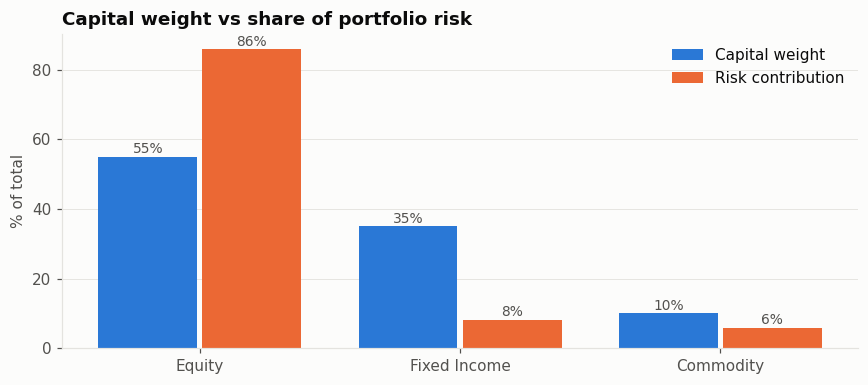

In [28]:
cov = R.cov() * 252
port_vol = float(np.sqrt(w @ cov @ w))
mcr = cov @ w / port_vol
risk = pd.DataFrame({'asset class': asset_stats['asset class'], 'weight %': 100 * w,
                     'standalone vol %': asset_stats['ann. vol %'], 'marginal contrib.': mcr,
                     'risk contribution %': 100 * w * mcr / port_vol})
rp = R @ w
q = np.quantile(rp, 0.01)
port_var = pd.Series({
    'portfolio annual vol %': 100 * port_vol,
    '1d VaR 99% parametric (USD)': V * (z99 * rp.std() - rp.mean()),
    '1d VaR 99% historical (USD)': -q * V,
    '1d ES 99% historical (USD)': -rp[rp <= q].mean() * V,
    'sum of standalone VaRs (USD)': (V * w * z99 * R.std()).sum(),
})
port_var['diversification benefit (USD)'] = port_var['sum of standalone VaRs (USD)'] - port_var['1d VaR 99% parametric (USD)']
display(risk)
display(port_var.to_frame('value'))

by_class = risk.groupby('asset class')[['weight %', 'risk contribution %']].sum().sort_values('weight %', ascending=False)
x = np.arange(len(by_class))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, by_class['weight %'], width=0.38, color=PALETTE[0], label='Capital weight')
ax.bar(x + 0.2, by_class['risk contribution %'], width=0.38, color=PALETTE[1], label='Risk contribution')
for i, (a, b) in enumerate(by_class.values):
    ax.text(i - 0.2, a + 1, f'{a:.0f}%', ha='center', fontsize=9, color=INK2); ax.text(i + 0.2, b + 1, f'{b:.0f}%', ha='center', fontsize=9, color=INK2)
ax.set_xticks(x, by_class.index); ax.set_ylabel('% of total'); ax.grid(axis='x', visible=False)
ax.set_title('Capital weight vs share of portfolio risk'); ax.legend()
fig.tight_layout(); save(fig, '11_weight_vs_risk'); plt.show()

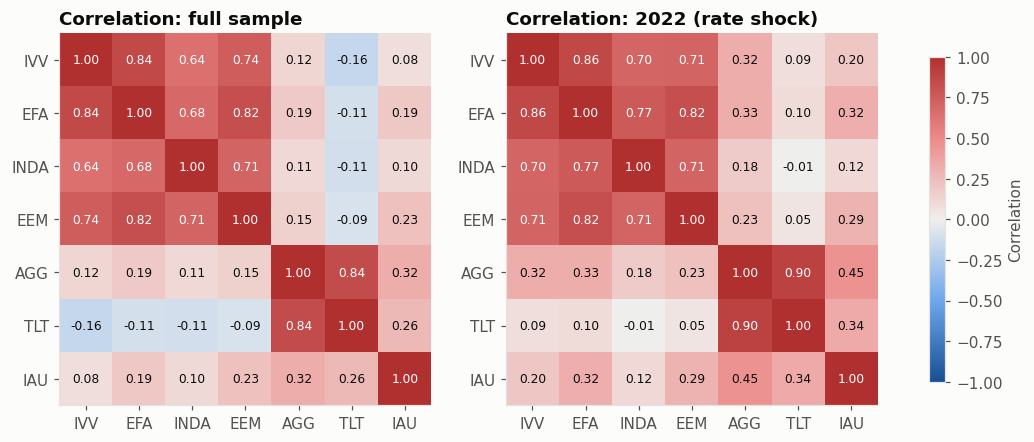

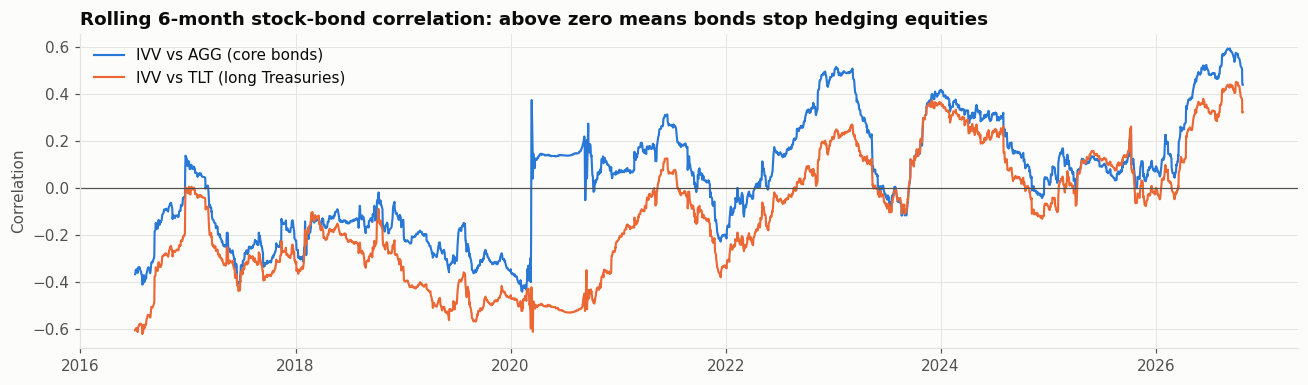

In [29]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list('div', ['#184f95', '#6da7ec', '#f0efec', '#ec8a89', '#b0302f'])
c_full = R.corr()
c_2022 = R.loc['2022'].corr() if len(R.loc['2022']) > 100 else c_full
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, c, title in [(axes[0], c_full, 'Correlation: full sample'), (axes[1], c_2022, 'Correlation: 2022 (rate shock)')]:
    im = ax.imshow(c.values, cmap=div, vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns); ax.set_yticks(range(len(c)), c.index); ax.grid(False)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f'{c.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(c.iloc[i, j]) > 0.6 else INK)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.8, label='Correlation')
save(fig, '12_correlation'); plt.show()

roll_c = pd.DataFrame({'IVV vs AGG (core bonds)': R['IVV'].rolling(126).corr(R['AGG']),
                       'IVV vs TLT (long Treasuries)': R['IVV'].rolling(126).corr(R['TLT'])}).dropna()
fig, ax = plt.subplots(figsize=(12, 3.6))
for col, c in zip(roll_c, PALETTE):
    ax.plot(roll_c.index, roll_c[col], color=c, lw=1.4, label=col)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_title('Rolling 6-month stock-bond correlation: above zero means bonds stop hedging equities'); ax.set_ylabel('Correlation'); ax.legend(loc='upper left')
fig.tight_layout(); save(fig, '13_stock_bond_corr'); plt.show()

,COVID-19 crash,2022 rate shock,Q4-2018 sell-off
IVV,"-101,709.00","-72,881.00","-58,152.00"
EFA,"-32,599.00","-27,707.00","-16,178.00"
INDA,"-41,910.00","-13,439.00","-5,255.00"
EEM,"-15,397.00","-14,938.00","-4,993.00"
AGG,"-3,360.00","-37,776.00","4,092.00"
TLT,"14,234.00","-30,588.00","4,531.00"
IAU,"-3,634.00","-9,019.00","5,013.00"
Portfolio,"-184,375.00","-206,348.00","-70,942.00"


,COVID-19 crash,2022 rate shock,Q4-2018 sell-off
loss / 10d VaR99,3.58,4.00,1.38


Worst scenario: 2022 rate shock (USD -206,348), which is 4.0x the 10-day 99% VaR. VaR alone would have understated it.
In 2022 bonds fell alongside equities (AGG and TLT both lost), so the 35% fixed-income sleeve added to losses instead of hedging.


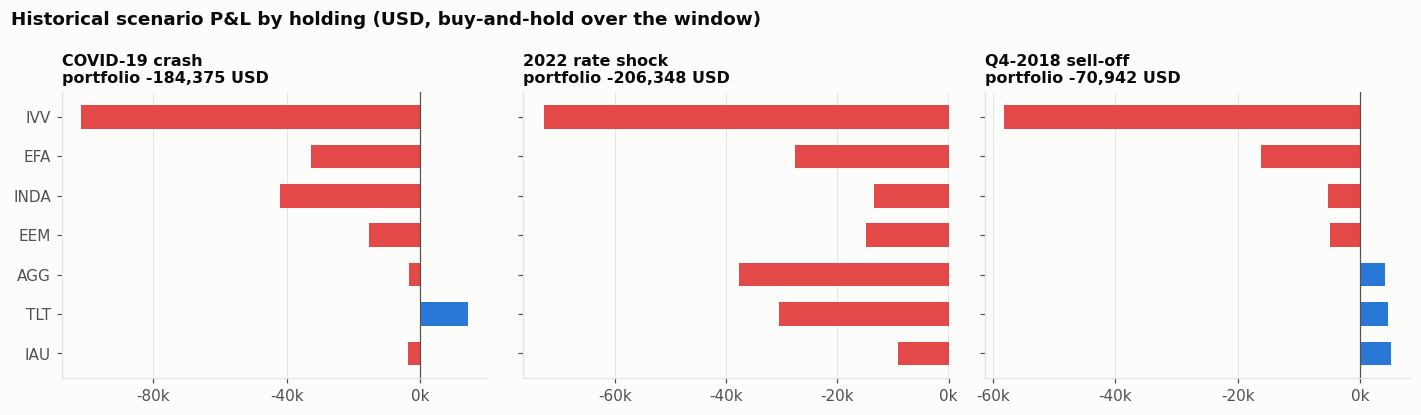

In [30]:
SCENARIOS = {'COVID-19 crash': ('2020-02-19', '2020-03-23'), '2022 rate shock': ('2022-01-03', '2022-10-14'),
             'Q4-2018 sell-off': ('2018-09-20', '2018-12-24')}
scen = {}
for name, (s, e) in SCENARIOS.items():
    sub = prices.loc[s:e]
    if len(sub) > 2:
        scen[name] = w * V * (sub.iloc[-1] / sub.iloc[0] - 1)
scen = pd.DataFrame(scen)
scen.loc['Portfolio'] = scen.sum()
port_10d_var = port_var['1d VaR 99% historical (USD)'] * np.sqrt(10)
summary_row = (-scen.loc['Portfolio'] / port_10d_var).rename('loss / 10d VaR99')
display(scen.round(0))
display(summary_row.to_frame().T)
worst_scen = scen.loc['Portfolio'].idxmin()
print(f"Worst scenario: {worst_scen} (USD {scen.loc['Portfolio', worst_scen]:,.0f}), which is "
      f"{summary_row[worst_scen]:.1f}x the 10-day 99% VaR. VaR alone would have understated it.")
if '2022 rate shock' in scen and '2022 rate shock' == worst_scen:
    print('In 2022 bonds fell alongside equities (AGG and TLT both lost), so the 35% fixed-income sleeve added to losses instead of hedging.')

fig, axes = plt.subplots(1, len(scen.columns), figsize=(13, 3.8), sharey=True)
for ax, col in zip(np.atleast_1d(axes), scen.columns):
    vals = scen.loc[TICKERS, col]
    ax.barh(TICKERS, vals, color=[PALETTE[0] if v >= 0 else PALETTE[7] for v in vals], height=0.6)
    ax.axvline(0, color=INK2, lw=0.8); ax.grid(axis='y', visible=False)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4)); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda x, _: f'{x / 1000:,.0f}k'))
    ax.set_title(f"{col}\nportfolio {scen.loc['Portfolio', col]:+,.0f} USD", fontsize=10.5)
np.atleast_1d(axes)[0].invert_yaxis()
fig.suptitle('Historical scenario P&L by holding (USD, buy-and-hold over the window)', x=0.01, ha='left', fontsize=12, fontweight='semibold')
fig.tight_layout(); save(fig, '14_portfolio_scenarios'); plt.show()

Drift since 23-Oct-2025 | tolerance: 5pp absolute or 20% relative | rebalancing turnover 4.6% (USD 45,589)


,target %,current %,drift (pp),relative drift %,action
IVV,30.00,33.17,3.17,10.56,Within tolerance
EFA,10.00,10.81,0.81,8.09,Within tolerance
INDA,10.00,8.20,-1.80,-18.01,Within tolerance
EEM,5.00,5.58,0.58,11.61,Within tolerance
AGG,25.00,23.88,-1.12,-4.47,Within tolerance
TLT,10.00,9.00,-1.00,-10.04,Within tolerance
IAU,10.00,9.36,-0.64,-6.36,Within tolerance


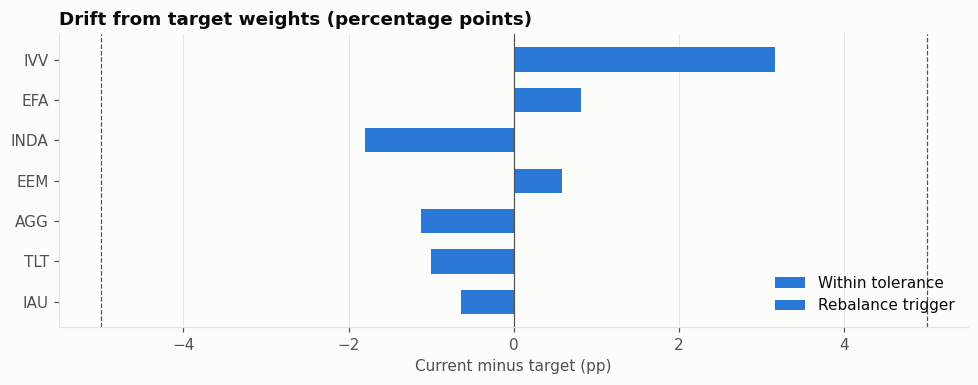

In [31]:
# Drift monitoring: target weights set 12 months ago, held without rebalancing
last = prices.iloc[-252:]
grown = w * last.iloc[-1] / last.iloc[0]
cur_w = grown / grown.sum()
drift = pd.DataFrame({'target %': 100 * w, 'current %': 100 * cur_w, 'drift (pp)': 100 * (cur_w - w),
                      'relative drift %': 100 * (cur_w / w - 1)})
drift['action'] = np.where((drift['drift (pp)'].abs() >= 5) | (drift['relative drift %'].abs() >= 20), 'Rebalance', 'Within tolerance')
turnover = 0.5 * (cur_w - w).abs().sum()
print(f'Drift since {last.index[0]:%d-%b-%Y} | tolerance: 5pp absolute or 20% relative | '
      f'rebalancing turnover {turnover:.1%} (USD {turnover * V:,.0f})')
display(drift)

fig, ax = plt.subplots(figsize=(9, 3.6))
breach = drift['action'] == 'Rebalance'
ax.barh(drift.index[~breach], drift.loc[~breach, 'drift (pp)'], color=PALETTE[0], height=0.6, label='Within tolerance')
ax.barh(drift.index[breach], drift.loc[breach, 'drift (pp)'], color=STATUS['serious'], height=0.6, label='Rebalance trigger')
for xv in (-5, 5):
    ax.axvline(xv, color=INK2, lw=0.8, ls='--')
ax.axvline(0, color=INK2, lw=0.8); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.set_title('Drift from target weights (percentage points)'); ax.set_xlabel('Current minus target (pp)'); ax.legend(loc='lower right')
fig.tight_layout(); save(fig, '15_drift'); plt.show()

## 11 · SQL analytics
Audit and data teams usually work in SQL against a warehouse. The results are loaded into a relational store (SQLite here; the same SQL works with minor changes on SQL Server, Snowflake or Postgres) and four typical queries are run: a yearly risk profile, a **pivot** of VaR exceptions by model and year (conditional aggregation), exception **clustering** (self-join with a CTE), and a **cross-check** between market anomalies and data-quality exceptions (LEFT JOIN plus triage logic).

In [32]:
con = sqlite3.connect(':memory:')
con.create_function('LN', 1, lambda v: math.log(v) if v is not None and v > 0 else None)
con.create_function('EXP', 1, lambda v: math.exp(v) if v is not None else None)
con.create_function('SQRT', 1, lambda v: math.sqrt(v) if v is not None and v >= 0 else None)
iso_date = lambda idx: pd.Index(idx).strftime('%Y-%m-%d')

pd.DataFrame({'date': iso_date(px.index), 'close': px.values, 'ret': px.pct_change().values}).to_sql('daily', con, index=False)
bt_long = (forecasts.stack().rename('var_pct').reset_index().rename(columns={'level_0': 'date', 'Date': 'date', 'level_1': 'model'}))
bt_long.columns = ['date', 'model', 'var_pct']
bt_long['ret'] = realised.reindex(pd.to_datetime(bt_long['date'])).values
bt_long['exception'] = (bt_long['ret'] < -bt_long['var_pct']).astype(int)
bt_long['date'] = iso_date(bt_long['date'])
bt_long.to_sql('var_backtest', con, index=False)
pd.DataFrame({'date': iso_date(register.index), 'ret_pct': (100 * register['ret']).round(2).values,
              'z_score': register['z_vol_adj'].round(2).values, 'n_methods': register['n_methods'].values,
              'priority': register['priority'].values}).to_sql('anomalies', con, index=False)
dq_log.assign(date=iso_date(dq_log['date']) if len(dq_log) else []).to_sql('dq_exceptions', con, index=False)

def run_sql(title, sql):
    print(f'-- {title}\n{sql.strip()}\n')
    return pd.read_sql_query(sql, con)

run_sql('Q1. Yearly risk profile', """
SELECT strftime('%Y', date)                                            AS year,
       COUNT(*)                                                        AS trading_days,
       ROUND(100 * (EXP(SUM(LN(1 + ret))) - 1), 2)                     AS annual_return_pct,
       ROUND(100 * SQRT(252 * (AVG(ret * ret) - AVG(ret) * AVG(ret))), 2) AS annualised_vol_pct,
       ROUND(100 * MIN(ret), 2)                                        AS worst_day_pct,
       SUM(CASE WHEN ABS(ret) > 0.03 THEN 1 ELSE 0 END)                AS days_over_3pct
FROM daily
WHERE ret IS NOT NULL
GROUP BY year
ORDER BY year;
""")

-- Q1. Yearly risk profile
SELECT strftime('%Y', date)                                            AS year,
       COUNT(*)                                                        AS trading_days,
       ROUND(100 * (EXP(SUM(LN(1 + ret))) - 1), 2)                     AS annual_return_pct,
       ROUND(100 * SQRT(252 * (AVG(ret * ret) - AVG(ret) * AVG(ret))), 2) AS annualised_vol_pct,
       ROUND(100 * MIN(ret), 2)                                        AS worst_day_pct,
       SUM(CASE WHEN ABS(ret) > 0.03 THEN 1 ELSE 0 END)                AS days_over_3pct
FROM daily
WHERE ret IS NOT NULL
GROUP BY year
ORDER BY year;



,year,trading_days,annual_return_pct,annualised_vol_pct,worst_day_pct,days_over_3pct
0,2016,244,3.91,14.78,-3.40,2
1,2017,248,27.91,8.91,-1.39,0
2,2018,246,5.91,12.56,-2.34,0
3,2019,241,14.38,13.87,-2.06,2
4,2020,249,15.75,32.00,-13.15,21
5,2021,247,21.99,15.84,-3.80,3
6,2022,248,4.44,17.45,-4.72,3
7,2023,245,18.74,9.88,-1.53,0
8,2024,245,8.17,14.01,-5.74,3
9,2025,248,9.06,11.66,-2.95,1


In [33]:
run_sql('Q2. VaR exceptions by year and model (pivot via conditional aggregation)', """
SELECT strftime('%Y', date)                                          AS year,
       SUM(CASE WHEN model = 'Normal'      THEN exception ELSE 0 END) AS normal,
       SUM(CASE WHEN model = 'Historical'  THEN exception ELSE 0 END) AS historical,
       SUM(CASE WHEN model = 'EWMA'        THEN exception ELSE 0 END) AS ewma,
       SUM(CASE WHEN model = 'Filtered HS' THEN exception ELSE 0 END) AS filtered_hs,
       COUNT(DISTINCT date)                                          AS test_days,
       ROUND(0.01 * COUNT(DISTINCT date), 1)                         AS expected_at_99pct
FROM var_backtest
GROUP BY year
ORDER BY year;
""")

-- Q2. VaR exceptions by year and model (pivot via conditional aggregation)
SELECT strftime('%Y', date)                                          AS year,
       SUM(CASE WHEN model = 'Normal'      THEN exception ELSE 0 END) AS normal,
       SUM(CASE WHEN model = 'Historical'  THEN exception ELSE 0 END) AS historical,
       SUM(CASE WHEN model = 'EWMA'        THEN exception ELSE 0 END) AS ewma,
       SUM(CASE WHEN model = 'Filtered HS' THEN exception ELSE 0 END) AS filtered_hs,
       COUNT(DISTINCT date)                                          AS test_days,
       ROUND(0.01 * COUNT(DISTINCT date), 1)                         AS expected_at_99pct
FROM var_backtest
GROUP BY year
ORDER BY year;



,year,normal,historical,ewma,filtered_hs,test_days,expected_at_99pct
0,2017,1,1,4,3,241,2.40
1,2018,9,8,2,2,246,2.50
2,2019,2,0,1,1,241,2.40
3,2020,10,10,12,7,249,2.50
4,2021,2,2,5,3,247,2.50
5,2022,7,3,5,2,248,2.50
6,2023,0,0,4,4,245,2.50
7,2024,6,6,4,3,245,2.50
8,2025,1,2,3,2,248,2.50
9,2026,8,6,4,4,199,2.00


In [34]:
run_sql('Q3. Exception clustering: exceptions with another exception within 5 calendar days', """
WITH ex AS (
    SELECT model, date FROM var_backtest WHERE exception = 1
)
SELECT a.model,
       COUNT(DISTINCT a.date)                                              AS exceptions,
       COUNT(DISTINCT CASE WHEN b.date IS NOT NULL THEN a.date END)        AS clustered,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN b.date IS NOT NULL THEN a.date END)
             / COUNT(DISTINCT a.date), 1)                                  AS clustered_pct
FROM ex a
LEFT JOIN ex b
       ON b.model = a.model
      AND b.date <> a.date
      AND ABS(julianday(a.date) - julianday(b.date)) <= 5
GROUP BY a.model
ORDER BY clustered_pct DESC;
""")

-- Q3. Exception clustering: exceptions with another exception within 5 calendar days
WITH ex AS (
    SELECT model, date FROM var_backtest WHERE exception = 1
)
SELECT a.model,
       COUNT(DISTINCT a.date)                                              AS exceptions,
       COUNT(DISTINCT CASE WHEN b.date IS NOT NULL THEN a.date END)        AS clustered,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN b.date IS NOT NULL THEN a.date END)
             / COUNT(DISTINCT a.date), 1)                                  AS clustered_pct
FROM ex a
LEFT JOIN ex b
       ON b.model = a.model
      AND b.date <> a.date
      AND ABS(julianday(a.date) - julianday(b.date)) <= 5
GROUP BY a.model
ORDER BY clustered_pct DESC;



,model,exceptions,clustered,clustered_pct
0,Historical,38,19,50.00
1,Normal,46,18,39.10
2,EWMA,44,11,25.00
3,Filtered HS,31,4,12.90


In [35]:
run_sql('Q4. High-priority anomalies cross-checked against data-quality exceptions', """
SELECT a.date,
       a.ret_pct,
       a.z_score,
       a.n_methods,
       COALESCE(GROUP_CONCAT(DISTINCT d.control_id), '-')               AS dq_flags_same_day,
       CASE WHEN COUNT(d.control_id) = 0
            THEN 'Market move: corroborate with news / second source'
            ELSE 'Possible data issue: verify before relying on it' END AS triage
FROM anomalies a
LEFT JOIN dq_exceptions d ON d.date = a.date
WHERE a.priority = 'High'
GROUP BY a.date, a.ret_pct, a.z_score, a.n_methods
ORDER BY ABS(a.ret_pct) DESC
LIMIT 12;
""")

-- Q4. High-priority anomalies cross-checked against data-quality exceptions
SELECT a.date,
       a.ret_pct,
       a.z_score,
       a.n_methods,
       COALESCE(GROUP_CONCAT(DISTINCT d.control_id), '-')               AS dq_flags_same_day,
       CASE WHEN COUNT(d.control_id) = 0
            THEN 'Market move: corroborate with news / second source'
            ELSE 'Possible data issue: verify before relying on it' END AS triage
FROM anomalies a
LEFT JOIN dq_exceptions d ON d.date = a.date
WHERE a.priority = 'High'
GROUP BY a.date, a.ret_pct, a.z_score, a.n_methods
ORDER BY ABS(a.ret_pct) DESC
LIMIT 12;



,date,ret_pct,z_score,n_methods,dq_flags_same_day,triage
0,2020-03-23,-13.15,-3.72,2,DQ-09,Possible data issue: verify before relying on it
1,2020-04-07,8.97,2.01,2,-,Market move: corroborate with news / second so...
2,2020-03-12,-8.18,-4.83,3,-,Market move: corroborate with news / second so...
3,2020-03-16,-7.96,-2.95,2,-,Market move: corroborate with news / second so...
4,2020-03-25,6.98,1.51,2,-,Market move: corroborate with news / second so...
5,2020-05-04,-5.94,-1.71,2,-,Market move: corroborate with news / second so...
6,2020-03-20,5.75,1.72,2,-,Market move: corroborate with news / second so...
7,2024-06-04,-5.74,-5.45,3,-,Market move: corroborate with news / second so...
8,2020-03-18,-5.59,-1.73,2,-,Market move: corroborate with news / second so...
9,2019-09-20,5.32,5.53,3,-,Market move: corroborate with news / second so...


**Closing the loop on a flagged item.** If 23-Mar-2020 shows *"Possible data issue"*, it is because the −13.15% move also tripped plausibility control DQ-09. The next step is corroboration: on that day the Sensex fell 3,934.72 points (29,915.96 → 25,981.24) as COVID-19 lockdowns spread. Public market reports confirm this, so the item is closed as a **genuine market move** and kept in the data. Every exception should end with a documented disposition like this.

## 12 · Power BI-ready export
The outputs are written as tidy **fact and dimension tables** (a star schema) with a **data dictionary**, so a Power BI report can refresh from them without rework.

**Suggested report (3 pages)**
1. *Risk overview*: KPI cards (1d VaR99, ES99, current EWMA vol, max drawdown), price and drawdown, VaR by method.
2. *Model validation*: traffic-light status per model, rolling exceptions, exceptions by year (matrix), stress losses.
3. *Data quality & exceptions*: control status table, exception log with slicers by control and date, anomaly register drill-through.

**Example DAX measures** (with a `dim_date` table related on `date`):
```DAX
Exceptions = SUM ( fact_var_backtest[exception] )
Exception Rate % = DIVIDE ( [Exceptions], COUNTROWS ( fact_var_backtest ) ) * 100
Exceptions (250d) =
    CALCULATE ( [Exceptions], DATESINPERIOD ( dim_date[date], MAX ( dim_date[date] ), -365, DAY ) )
Basel Zone =
    SWITCH ( TRUE (), [Exceptions (250d)] <= 4, "Green", [Exceptions (250d)] <= 9, "Yellow", "Red" )
Controls Failing = CALCULATE ( COUNTROWS ( dim_dq_controls ), dim_dq_controls[status] = "FAIL" )
```

In [36]:
PBI = os.path.join(CFG['out_dir'], 'powerbi')
fact_daily = pd.DataFrame({'date': px.index, 'close': px.values}).set_index('date')
fact_daily['return'] = px.pct_change()
fact_daily['drawdown'] = dd
fact_daily['ewma_vol_annual'] = ewma_vol / 100
fact_daily['realised_vol_21d_annual'] = roll_vol / 100
for m in forecasts:
    fact_daily[f'var99_{m.lower().replace(" ", "_")}'] = forecasts[m]
    fact_daily[f'exception_{m.lower().replace(" ", "_")}'] = hits[m].astype('Int64')
fact_daily['anomaly_methods'] = feat['n_methods'].reindex(fact_daily.index).fillna(0).astype(int)

exports = {
    'fact_daily_risk': fact_daily.reset_index(),
    'fact_var_backtest': bt_long,
    'fact_var_summary': var_table,
    'fact_backtest_summary': backtest.drop(columns=[c for c in backtest if c.startswith('_')]).reset_index(),
    'fact_stress_scenarios': pd.concat([vol_stress.assign(type='Volatility regime'), stress.assign(type='Historical / hypothetical')], ignore_index=True),
    'fact_anomaly_register': register.reset_index().rename(columns={'index': 'date', 'Date': 'date'}),
    'dim_dq_controls': dq_summary,
    'fact_dq_exceptions': dq_log,
    'fact_portfolio_risk': risk.reset_index().rename(columns={'index': 'ticker'}),
    'fact_portfolio_scenarios': scen.reset_index().rename(columns={'index': 'holding'}),
    'fact_portfolio_drift': drift.reset_index().rename(columns={'index': 'ticker'}),
    'dim_review_findings': findings,
}
DESCRIPTIONS = {
    'date': 'Trading date', 'close': 'Sensex closing level', 'return': 'Simple daily return (decimal)',
    'drawdown': 'Decline from running peak (decimal, <= 0)', 'ewma_vol_annual': 'EWMA volatility (lambda 0.94), annualised',
    'realised_vol_21d_annual': '21-day realised volatility, annualised', 'var_pct': '1-day 99% VaR forecast (decimal, positive = loss)',
    'exception': '1 if realised loss exceeded the VaR forecast', 'model': 'VaR model name', 'ret': 'Realised daily return (decimal)',
    'control_id': 'Data quality control identifier', 'status': 'PASS / REVIEW / FAIL (or remediation status for findings)',
    'exceptions': 'Count of records failing the control', 'detail': 'Context for the exception',
    'n_methods': 'Number of anomaly methods flagging the day (0-3)', 'priority': 'Triage priority (High = 2+ methods)',
    'risk contribution %': 'Share of portfolio volatility from the holding (Euler allocation)', 'drift (pp)': 'Current minus target weight, percentage points',
    'rating': 'Finding rating (High / Medium / Low)', 'anomaly_methods': 'Number of anomaly methods flagging the day',
}
dictionary = []
for name, df in exports.items():
    df.to_csv(os.path.join(PBI, f'{name}.csv'), index=False)
    for col in df.columns:
        desc = DESCRIPTIONS.get(col) or ('99% VaR forecast for the named model' if col.startswith('var99_') else
                                         'Exception flag for the named model' if col.startswith('exception_') else '')
        dictionary.append({'table': name, 'column': col, 'dtype': str(df[col].dtype), 'description': desc})
pd.DataFrame(dictionary).to_csv(os.path.join(PBI, 'data_dictionary.csv'), index=False)
print(f'Wrote {len(exports)} tables + data_dictionary.csv to {PBI}/')
pd.DataFrame({'table': list(exports), 'rows': [len(d) for d in exports.values()], 'columns': [d.shape[1] for d in exports.values()]})

Wrote 12 tables + data_dictionary.csv to outputs\powerbi/


,table,rows,columns
0,fact_daily_risk,2661,15
1,fact_var_backtest,9636,5
2,fact_var_summary,12,8
3,fact_backtest_summary,4,13
4,fact_stress_scenarios,18,12
5,fact_anomaly_register,29,13
6,dim_dq_controls,11,7
7,fact_dq_exceptions,32,3
8,fact_portfolio_risk,7,6
9,fact_portfolio_scenarios,8,4


## 13 · AI-drafted audit memo, with guardrails
LLMs are good at drafting and bad at being trusted with numbers. Practical **AI fluency** means designing the workflow so the model cannot quietly introduce errors:

1. **Grounding**: the model only sees a `FACTS` JSON built from the calculations above and is told to quote figures exactly.
2. **Automatic verification**: every number in the draft is extracted and traced back to `FACTS`. Anything that cannot be traced is flagged.
3. **Testing the check itself**: a deliberately tampered draft must be caught, otherwise the guardrail is not trusted.
4. **Human sign-off**: the output is always marked *DRAFT – requires reviewer approval*. The AI accelerates the work; it does not sign off.

If no `ANTHROPIC_API_KEY` is available (Colab secret or environment variable), a deterministic template memo goes through the same checks, so the notebook always runs.

In [37]:
bt_n, bt_f = backtest.loc['Normal'], backtest.loc[best_model]
eq_risk = risk.loc[risk['asset class'] == 'Equity', 'risk contribution %'].sum()
eq_weight = 100 * w[[t for t in TICKERS if MODEL[t]['asset_class'] == 'Equity']].sum()
FACTS = {
    'data_source': SOURCE, 'period': f'{ret.index.min():%d-%b-%Y} to {ret.index.max():%d-%b-%Y}', 'observations': len(ret),
    'dq_controls_run': len(dq_summary), 'dq_controls_fail': int(n_fail), 'dq_controls_review': int(n_review),
    'position_inr': f'{POS:,.0f}', 'var_horizon_days': 1,
    'annual_vol_pct': round(100 * ret.std() * np.sqrt(252), 1),
    'original_reported_annual_vol_pct': round(100 * REPORTED['annualised_vol'], 1),
    'correct_annual_vol_original_sample_pct': round(100 * ann_correct, 1),
    'excess_kurtosis': round(stats.kurtosis(ret), 1),
    'var99_1d_normal_inr': f"{v99.loc['Parametric normal', '1d VaR (INR)']:,.0f}",
    'var99_1d_historical_inr': f"{v99.loc['Historical simulation', '1d VaR (INR)']:,.0f}",
    'es99_1d_historical_inr': f"{v99.loc['Historical simulation', '1d ES (INR)']:,.0f}",
    'backtest_confidence_pct': 99, 'backtest_window_days': W, 'backtest_test_days': int(bt_n['test days']),
    'normal_model_exceptions': int(bt_n['exceptions']), 'expected_exceptions': float(bt_n['expected']),
    'normal_model_pct_days_red_zone': round(float(bt_n['% of days in Red']), 1),
    'normal_model_verdict': bt_n['verdict'], 'recommended_model': best_model,
    'recommended_model_exceptions': int(bt_f['exceptions']), 'recommended_model_verdict': bt_f['verdict'],
    'worst_day_pct': round(100 * ret.min(), 2), 'worst_day': f'{ret.idxmin():%d-%b-%Y}',
    'max_drawdown_pct': round(100 * dd.min(), 1),
    'findings_high': int((findings['rating'] == 'High').sum()), 'findings_medium': int((findings['rating'] == 'Medium').sum()),
    'findings_low': int((findings['rating'] == 'Low').sum()),
    'portfolio_equity_weight_pct': round(eq_weight), 'portfolio_equity_risk_share_pct': round(eq_risk),
    'portfolio_2022_loss_usd': f"{-scen.loc['Portfolio', '2022 rate shock']:,.0f}" if '2022 rate shock' in scen else 'n/a',
    'portfolio_value_usd': f'{V:,.0f}',
}

def template_memo(f):
    return f"""**Subject:** Independent review of the Sensex VaR model ({f['period']})

**Scope.** We re-performed and extended the market-risk model using {f['observations']} daily observations from {f['data_source']}. {f['dq_controls_run']} data quality controls were run: {f['dq_controls_fail']} failed and {f['dq_controls_review']} needed review.

**Key findings**
- Volatility was annualised incorrectly: {f['original_reported_annual_vol_pct']}% was reported against a correct {f['correct_annual_vol_original_sample_pct']}%.
- Returns are fat-tailed (excess kurtosis {f['excess_kurtosis']}). The normal model's 1-day 99% VaR of INR {f['var99_1d_normal_inr']} compares with INR {f['var99_1d_historical_inr']} under historical simulation, and the historical Expected Shortfall is INR {f['es99_1d_historical_inr']}.
- In a {f['backtest_test_days']}-day out-of-sample backtest, the normal model had {f['normal_model_exceptions']} exceptions against {f['expected_exceptions']} expected and spent {f['normal_model_pct_days_red_zone']}% of days in the Basel Red zone (verdict: {f['normal_model_verdict']}).
- The worst day was {f['worst_day_pct']}% on {f['worst_day']}; the maximum drawdown was {f['max_drawdown_pct']}%.

**Overall rating:** {f['findings_high']} High, {f['findings_medium']} Medium and {f['findings_low']} Low findings.

**Management actions**
- Adopt {f['recommended_model']} as the primary VaR model ({f['recommended_model_exceptions']} exceptions; verdict: {f['recommended_model_verdict']}) and report Expected Shortfall alongside VaR.
- Run the automated data quality controls and backtest every month, with results in the Power BI dashboard.
- For multi-asset clients, report risk contribution as well as weight: equities are {f['portfolio_equity_weight_pct']}% of capital but {f['portfolio_equity_risk_share_pct']}% of risk.
"""

NUM = re.compile(r'(?<![\w.])-?\d[\d,]*(?:\.\d+)?')

def numbers_in(text):
    text = re.sub(r'(?m)^\s*(?:[-*]|\d+[.)])\s+', '', text)   # ignore list markers
    out = []
    for tok in NUM.findall(text):
        try:
            out.append((tok, float(tok.replace(',', ''))))
        except ValueError:
            pass
    return out

def verify_against_facts(text, facts, rel_tol=0.005, abs_tol=0.051):
    allowed = [v for _, v in numbers_in(json.dumps(facts))]
    rows = []
    for tok, v in numbers_in(text):
        ok = any(abs(abs(v) - abs(a)) <= max(abs_tol, rel_tol * abs(a)) for a in allowed)
        rows.append({'figure in draft': tok, 'traced to FACTS': ok})
    report = pd.DataFrame(rows)
    return report, bool(report['traced to FACTS'].all()) if len(report) else True

draft = template_memo(FACTS)
rep, ok = verify_against_facts(draft, FACTS)
print(f"Template draft: {len(rep)} figures checked -> {'PASS, all traced' if ok else 'FLAG'}")
if not ok:
    display(rep[~rep['traced to FACTS']])

# The check must catch an injected error, otherwise it is not trusted
tok = numbers_in(FACTS['var99_1d_historical_inr'])[0][0]
tampered = draft.replace(tok, f'{float(tok.replace(",", "")) * 1.37:,.0f}', 1)
_, ok_tampered = verify_against_facts(tampered, FACTS)
assert not ok_tampered, 'Guardrail failed to detect a fabricated figure'
print('Tamper test     : fabricated VaR figure detected -> guardrail works')

Template draft: 30 figures checked -> PASS, all traced
Tamper test     : fabricated VaR figure detected -> guardrail works


In [38]:
SYSTEM_PROMPT = """You draft internal audit memos for an audit committee audience.
Use only the figures in the FACTS JSON you are given, and quote each one exactly as written there:
no unit conversions, no rounding changes and no new calculations. If a point needs a number that is
not in FACTS, describe it qualitatively. Structure: Subject line; Scope (2 sentences); Key findings
(3-5 bullets, each citing its evidence figure); Overall rating with rationale; Management actions
(3 bullets). Plain business English, under 300 words."""

def get_api_key():
    key = os.environ.get('ANTHROPIC_API_KEY')
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get('ANTHROPIC_API_KEY')
        except Exception:
            key = None
    return key

def draft_with_claude(facts):
    key = get_api_key()
    if not key:
        return None, 'No ANTHROPIC_API_KEY found: using the deterministic template.'
    try:
        import anthropic
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'anthropic'], check=True)
        import anthropic
    client = anthropic.Anthropic(api_key=key)
    try:
        resp = client.beta.messages.create(
            model='claude-opus-5-5', max_tokens=16000,
            betas=['server-side-fallback-2026-07-01'], fallbacks='default',   # retry on a fallback model if declined
            output_config={'effort': 'medium'},
            system=SYSTEM_PROMPT,
            messages=[{'role': 'user', 'content': 'FACTS (JSON):\n' + json.dumps(facts, indent=2)}],
        )
    except anthropic.APIStatusError as exc:
        return None, f'API error {exc.status_code}: using the deterministic template.'
    except anthropic.APIConnectionError:
        return None, 'Network error: using the deterministic template.'
    if resp.stop_reason == 'refusal':
        return None, 'Model declined: using the deterministic template.'
    return ''.join(b.text for b in resp.content if b.type == 'text'), f'Drafted by {resp.model}'

llm_draft, note = draft_with_claude(FACTS)
print(note)
final, author = draft, 'deterministic template'
if llm_draft:
    rep_llm, ok_llm = verify_against_facts(llm_draft, FACTS)
    print(f"LLM draft: {len(rep_llm)} figures checked -> {'PASS' if ok_llm else 'FLAG: untraced figures below'}")
    if not ok_llm:
        display(rep_llm[~rep_llm['traced to FACTS']])
    final, author = (llm_draft, 'Claude') if ok_llm else (draft, 'deterministic template (LLM draft rejected by guardrail)')

final_rep, final_ok = verify_against_facts(final, FACTS)
check = (f'all {len(final_rep)} figures traced to model output' if final_ok
         else f"{(~final_rep['traced to FACTS']).sum()} figure(s) NOT traced: reviewer must check before use")
memo = f"> DRAFT - requires reviewer approval. Prepared by: {author}. Number check: {check}.\n\n{final}"
with open(os.path.join(CFG['out_dir'], 'audit_memo.md'), 'w', encoding='utf-8') as fh:
    fh.write(memo)
from IPython.display import Markdown
Markdown(memo)

No ANTHROPIC_API_KEY found: using the deterministic template.


> DRAFT - requires reviewer approval. Prepared by: deterministic template. Number check: all 30 figures traced to model output.

**Subject:** Independent review of the Sensex VaR model (05-Jan-2016 to 23-Oct-2026)

**Scope.** We re-performed and extended the market-risk model using 2660 daily observations from Yahoo Finance via yfinance (^BSESN). 11 data quality controls were run: 0 failed and 4 needed review.

**Key findings**
- Volatility was annualised incorrectly: 14.9% was reported against a correct 18.4%.
- Returns are fat-tailed (excess kurtosis 18.9). The normal model's 1-day 99% VaR of INR 233,833 compares with INR 261,562 under historical simulation, and the historical Expected Shortfall is INR 435,756.
- In a 2409-day out-of-sample backtest, the normal model had 46 exceptions against 24.1 expected and spent 10.0% of days in the Basel Red zone (verdict: Reject).
- The worst day was -13.15% on 23-Mar-2020; the maximum drawdown was -38.1%.

**Overall rating:** 3 High, 4 Medium and 3 Low findings.

**Management actions**
- Adopt Filtered HS as the primary VaR model (31 exceptions; verdict: Accept) and report Expected Shortfall alongside VaR.
- Run the automated data quality controls and backtest every month, with results in the Power BI dashboard.
- For multi-asset clients, report risk contribution as well as weight: equities are 55% of capital but 86% of risk.


## 14 · Summary of results & recommendations

In [39]:
summary = pd.Series({
    'Data source / period': f"{SOURCE} | {FACTS['period']}",
    'Data quality': f"{len(dq_summary)} controls: {n_fail} FAIL, {n_review} REVIEW; {recon['removed'].sum()} records removed",
    'Original model re-performance': f"daily vol agrees to {reperf.loc[0, 'difference_%']:+.1f}%; 10 findings ({FACTS['findings_high']} High)",
    'Annualised volatility': f"{FACTS['annual_vol_pct']}% (excess kurtosis {FACTS['excess_kurtosis']})",
    '1d 99% VaR: normal vs historical': f"INR {FACTS['var99_1d_normal_inr']} vs INR {FACTS['var99_1d_historical_inr']}",
    '1d 99% Expected Shortfall (hist.)': f"INR {FACTS['es99_1d_historical_inr']}",
    'Backtest: normal model': f"{FACTS['normal_model_exceptions']} exceptions vs {FACTS['expected_exceptions']} expected; {FACTS['normal_model_pct_days_red_zone']}% of days Red; {FACTS['normal_model_verdict']}",
    'Backtest: recommended model': f"{best_model}: {FACTS['recommended_model_exceptions']} exceptions; {FACTS['recommended_model_verdict']}",
    'Worst day / max drawdown': f"{FACTS['worst_day_pct']}% ({FACTS['worst_day']}) / {FACTS['max_drawdown_pct']}%",
    'Anomalies': f"{len(register)} flagged, {(register['priority'] == 'High').sum()} High priority",
    'Model portfolio': f"vol {port_var['portfolio annual vol %']:.1f}%; equities {FACTS['portfolio_equity_weight_pct']}% of weight, {FACTS['portfolio_equity_risk_share_pct']}% of risk; 2022 loss USD {FACTS['portfolio_2022_loss_usd']}",
    'Drift': f"{(drift['action'] == 'Rebalance').sum()} holding(s) breach tolerance; turnover {turnover:.1%}",
}, name='result')
summary.to_frame()

,result
Data source / period,Yahoo Finance via yfinance (^BSESN) | 05-Jan-2...
Data quality,"11 controls: 0 FAIL, 4 REVIEW; 0 records removed"
Original model re-performance,daily vol agrees to +0.2%; 10 findings (3 High)
Annualised volatility,16.3% (excess kurtosis 18.9)
1d 99% VaR: normal vs historical,"INR 233,833 vs INR 261,562"
1d 99% Expected Shortfall (hist.),"INR 435,756"
Backtest: normal model,46 exceptions vs 24.1 expected; 10.0% of days ...
Backtest: recommended model,Filtered HS: 31 exceptions; Accept
Worst day / max drawdown,-13.15% (23-Mar-2020) / -38.1%
Anomalies,"29 flagged, 15 High priority"


### Recommendations
1. **Replace the normal VaR model** with the model recommended by the backtest, and report **Expected Shortfall** alongside VaR at 99% for 1-day and 10-day horizons.
2. **Backtest every month** and escalate automatically when a model enters the Yellow or Red zone. Validation is a recurring control, not a one-off exercise.
3. **Run the data-quality controls on every data load.** FAIL controls should block downstream use, and REVIEW items should be corroborated against a second source.
4. **Use volatility-adjusted anomaly detection** for continuous monitoring, triaged by how many methods agree.
5. **Report risk contribution as well as weight** for multi-asset portfolios, and stress-test for regimes where stocks and bonds fall together (2022).
6. **Keep a human in the loop for AI-drafted reporting.** Number-level verification against source data should be required before sign-off.

### Limitations & next steps
* √10 scaling assumes independent returns. Volatility clustering makes it optimistic in a crisis. *Next:* GARCH(1,1) or direct multi-day historical simulation.
* VaR covers a single linear position. *Next:* include options and FX for an INR investor in the US-listed ETFs.
* The portfolio uses daily-rebalanced returns for risk statistics but buy-and-hold for scenarios. Both are stated, but they differ by design.
* Event annotations are analyst notes and should be corroborated with a news source before going in a report.
* *Productionising:* schedule the notebook (Airflow / Azure Data Factory), write the tables to a SQL warehouse, and point the Power BI dataset at it for scheduled refresh.